# Reusing my frozen BERTopic question assignments
**David · Cambridge / Bank of England employer project**

I provide the primary `L25` assignment for every R1C5 analyst question so teammates can join their own measurements using `question_unit_id`.

This companion covers four operations: load the assignments, inspect their population, attach a question-level feature table, and reproduce the original-denominator question shares. The example feature table contains the existing saved FinBERT scores. All inputs required for these examples are supplied in this folder.

The final analysis notebooks remain the source for my research findings. This notebook is a reusable data interface.

## 1 Verified inputs

I keep one `L25` row per question. The original research file contains six model runs; the companion selects the fixed primary run before any join.

Open this notebook inside `bertopic_assignment_reuse`, or set `BOE_REUSE_DIR` to that folder. The functions below check the asset inventory and hashes before loading. Dependencies are listed in `requirements-reuse.txt`.

In [ ]:
from pathlib import Path
import os, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ID = "question_unit_id"
RELEASE = "personal-r1c5-v1-f43132bb41508cb3"
MODEL = "L25"
THEMES = ["T4", "T5", "T7", "T8", "T9", "T13", "T15"]
STATUS_COUNTS = {"RETAIN": 330, "MIXED_UNRESOLVED": 498,
                 "CONVERSATIONAL": 148, "NOISE": 557, "NOT_FITTED": 367}
MANIFEST_HASH = 'e6a89653236866d30ae0b796473a59411c913987e39f35964e71a35e35668880'
PROVENANCE_HASH = 'c34153ad3a712ef2d1f04e6a50408ced87d82b37f779b1d678667ced7bb03f37'


def find_reuse_package(start=None):
    # Works in the extracted companion or from the team repository.
    explicit = os.environ.get("BOE_REUSE_DIR")
    root = Path(explicit or start or Path.cwd()).expanduser().resolve()
    roots = [root] if explicit else [root, *root.parents]
    for base in roots:
        for candidate in [base, base / "bertopic_assignment_reuse",
                          base / "david/cambridge_boe_r1c5/bertopic_assignment_reuse"]:
            if (candidate / "assets/ASSET_MANIFEST.json").is_file():
                return candidate
    raise FileNotFoundError("Open the companion folder or set BOE_REUSE_DIR.")


def read_asset(package, name):
    # Verify the inventory, then the exact requested CSV bytes.
    package = Path(package)
    inventory_bytes = (package / "assets/ASSET_MANIFEST.json").read_bytes()
    if hashlib.sha256(inventory_bytes).hexdigest() != MANIFEST_HASH:
        raise ValueError("Asset manifest differs from this notebook's pinned inventory.")
    inventory = json.loads(inventory_bytes)
    if name not in inventory or Path(name).name != name:
        raise ValueError("Use a registered asset filename.")
    path = package / "assets" / name
    if hashlib.sha256(path.read_bytes()).hexdigest() != inventory[name]["sha256"]:
        raise ValueError(f"Asset changed: {name}")
    return pd.read_csv(path, float_precision="round_trip", dtype={
        ID: "string", "source_topic": "string", "category_id": "string",
        "reviewed_theme_id": "string"})


def read_provenance(package):
    data = (Path(package) / "PROVENANCE.json").read_bytes()
    if hashlib.sha256(data).hexdigest() != PROVENANCE_HASH:
        raise ValueError("Provenance record changed.")
    return json.loads(data)


def check_question_keys(frame, name):
    # A feature table must have one canonical ID per row.
    if not isinstance(frame, pd.DataFrame) or frame.columns.has_duplicates:
        raise ValueError(f"{name}: expected a DataFrame with unique columns.")
    if ID not in frame.columns:
        raise ValueError(f"{name}: missing {ID}.")
    ids = frame[ID]
    if ids.isna().any() or not all(isinstance(x, str) for x in ids.tolist()):
        raise ValueError(f"{name}: question IDs must be non-missing strings.")
    if not ids.str.fullmatch(r"question_[0-9a-f]{16}").all():
        raise ValueError(f"{name}: use exact R1C5 question IDs; whitespace/altered IDs are rejected.")
    if ids.duplicated().any():
        raise ValueError(f"{name}: duplicate question IDs; aggregate repeated observations first.")


def show_table(frame, caption):
    display(HTML('<div style="overflow-x:auto;max-width:100%">' +
                 frame.to_html(index=True, border=0, na_rep="Unavailable") + '</div>'))
    print(caption)

In [ ]:
PACKAGE = find_reuse_package()
provenance = read_provenance(PACKAGE)
assignments = read_asset(PACKAGE, "question_assignments.csv")
mapping = read_asset(PACKAGE, "fixed_topic_mapping.csv")
print(f"Loaded {len(assignments):,} {MODEL} assignments from {RELEASE}.")

Loaded 1,900 L25 assignments from personal-r1c5-v1-f43132bb41508cb3.


## 2 Assignment population and labels

The 1,900 rows cover 60 calls from BAC, Citi and JPM across 2021Q1–2025Q4. The primary fit used 1,533 questions; the other 367 retain their excluded-from-fit status. The mapping was independently reviewed and supplies seven narrow theme proxies.

| Field | Meaning |
|---|---|
| `question_unit_id` | Unique canonical question key for joining |
| `model_run`, `source_topic` | Run-scoped BERTopic assignment; topic IDs belong to `L25` |
| `category_id` | Fixed category, including source-specific accounting buckets |
| `reviewed_theme_id`, `reviewed_theme_label` | Populated for the seven retained proxies |
| `assignment_status` | RETAIN, MIXED_UNRESOLVED, CONVERSATIONAL, NOISE or NOT_FITTED |
| `membership_strength` | Saved cluster membership strength; missing outside the fit |
| `question_text_sha256` | Hash of exact UTF-8 question text used in the saved analysis |
| `reference_text_sha256` | Original parser reference-text hash; a separate identity field |

I count each question once. Membership strength describes the saved clustering and is separate from semantic label accuracy. The full field dictionary is in `DATA_DICTIONARY.md`.

In [ ]:
def validate_assignments(assignments, mapping):
    check_question_keys(assignments, "Assignments")
    required = {"corpus_release", "model_run", "call_id", "bank_id", "fiscal_period", "t",
                "source_topic", "category_id", "assignment_status", "reviewed_theme_id",
                "reviewed_theme_label", "membership_strength", "in_primary_fit", "human_validated"}
    if not required.issubset(assignments.columns):
        raise ValueError("Assignment schema is incomplete.")
    if len(assignments) != 1900 or not assignments.corpus_release.eq(RELEASE).all():
        raise ValueError("Use the complete 1,900-question release as the denominator population.")
    if not assignments.model_run.eq(MODEL).all():
        raise ValueError("Expected primary L25 assignments only.")
    if len(mapping) != 18 or mapping.source_topic.duplicated().any():
        raise ValueError("Expected the frozen 18-bucket crosswalk.")

    # Verify source topic -> category/status/label, including accounting buckets.
    mapped = mapping.set_index("source_topic").reindex(assignments.source_topic)
    pairs = [("category_id", "category_id"), ("assignment_status", "action"),
             ("reviewed_theme_label", "target_label")]
    for left, right in pairs:
        if assignments[left].fillna("").astype(str).tolist() != mapped[right].fillna("").astype(str).tolist():
            raise ValueError(f"Fixed mapping mismatch: {left}")
    retained = assignments.assignment_status.eq("RETAIN")
    if not assignments.loc[retained, "reviewed_theme_id"].eq(assignments.loc[retained, "category_id"]).all():
        raise ValueError("Retained theme ID differs from its fixed category.")
    if assignments.loc[~retained, "reviewed_theme_id"].notna().any():
        raise ValueError("Accounting rows must retain an unavailable reviewed-theme ID.")
    if assignments.assignment_status.value_counts().to_dict() != STATUS_COUNTS:
        raise ValueError("Frozen assignment-status counts changed.")
    if not assignments.in_primary_fit.eq(assignments.source_topic.ne("NOT_FITTED_LEGACY_COHORT")).all():
        raise ValueError("Primary fitting status differs from the source assignment.")
    if not assignments.human_validated.eq(False).all():
        raise ValueError("Frozen validation flags changed.")
    outside = ~assignments.in_primary_fit
    if assignments.loc[outside, "membership_strength"].notna().any():
        raise ValueError("Excluded-from-fit membership must stay unavailable.")
    if not assignments.loc[assignments.in_primary_fit, "membership_strength"].between(0, 1).all():
        raise ValueError("Invalid membership strength.")
    if not assignments.loc[assignments.assignment_status.eq("NOISE"), "membership_strength"].eq(0).all():
        raise ValueError("Noise membership differs from the frozen output.")

    # Complete three-bank calendar; one call per bank-quarter.
    calls = assignments[["call_id", "bank_id", "fiscal_period", "t"]].drop_duplicates()
    expected = {(b, f"{y}Q{q}") for b in ["BAC", "CITI", "JPM"]
                for y in range(2021, 2026) for q in range(1, 5)}
    if len(calls) != 60 or calls.call_id.duplicated().any() or set(zip(calls.bank_id, calls.fiscal_period)) != expected:
        raise ValueError("Incomplete or inconsistent bank-quarter grid.")
    quarter_index = calls.fiscal_period.map(lambda x: (int(x[:4])-2021)*4 + int(x[-1])-1)
    if not calls.t.eq(quarter_index).all():
        raise ValueError("Quarter indices changed.")
    return {"questions": len(assignments), "calls": len(calls),
            "in_primary_fit": int(assignments.in_primary_fit.sum()),
            "retained_questions": int(retained.sum())}

,Questions,Share of all questions (%)
assignment_status,,
RETAIN,330,17.37
MIXED_UNRESOLVED,498,26.21
CONVERSATIONAL,148,7.79
NOISE,557,29.32
NOT_FITTED,367,19.32


Table 1. Primary question assignments: all 1,900 rows.


,questions,calls
bank_id,,
BAC,625,20
CITI,471,20
JPM,804,20


Table 2. Question and call coverage by bank.


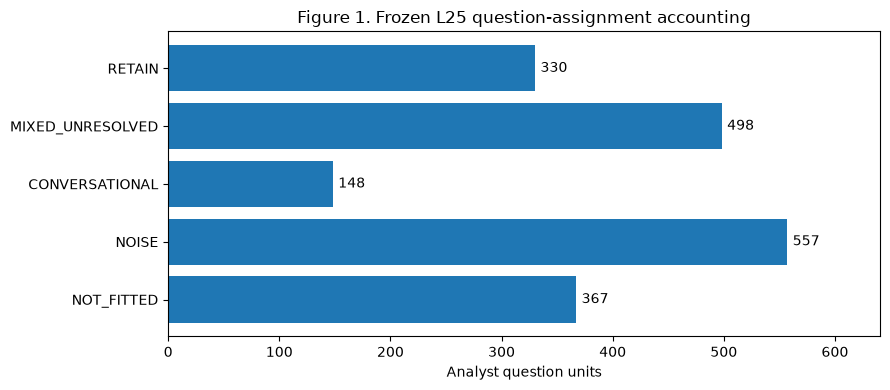

In [ ]:
population_check = validate_assignments(assignments, mapping)
status_order = list(STATUS_COUNTS)
status_table = (assignments.groupby("assignment_status").size()
                .reindex(status_order).rename("Questions").to_frame())
status_table["Share of all questions (%)"] = 100 * status_table.Questions / len(assignments)
show_table(status_table.round(2), "Table 1. Primary question assignments: all 1,900 rows.")
show_table(assignments.groupby("bank_id").agg(questions=(ID, "size"), calls=("call_id", "nunique")),
           "Table 2. Question and call coverage by bank.")

# Display all five statuses; the same counts appear in Table 1.
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(status_order, status_table.Questions)
for y, value in enumerate(status_table.Questions):
    ax.text(value + 5, y, str(value), va="center")
ax.set_xlim(0, status_table.Questions.max() * 1.15)
ax.set_xlabel("Analyst question units")
ax.set_title("Figure 1. Frozen L25 question-assignment accounting")
ax.invert_yaxis()
fig.tight_layout()
plt.show()
plt.close(fig)

**What is shown.** The mapping retains 330 questions across seven themes. It also preserves 498 mixed/unresolved, 148 conversational, 557 noise and 367 excluded-from-fit questions. BAC contributes 625 questions, Citi 471 and JPM 804, with 20 calls per bank. Every one of these rows remains available for a feature join. [Tables 1–2; Figure 1]

## 3 Join contract

I join on the exact canonical question ID and keep all assignment rows. A supplied feature table has one row per question; repeated sentence/window measurements need an explicit question-level aggregation first.

The function checks duplicate and foreign IDs, overlapping feature names and any shared call/text/source metadata. A complete join is required by default. For a deliberate subset, `require_complete=False` keeps missing feature rows visible and records their count.

Matched rows can still have missing feature values. The returned audit reports row matching and value missingness separately. Include `call_id` and `question_text_sha256` in your feature output where possible; matching a different parser hash requires `reference_text_sha256` instead.

In [ ]:
def attach_question_features(assignments, features, feature_columns, *, require_complete=True):
    """Left-join one feature row per canonical question; return data and a join audit.

    Metadata is checked when supplied. Missing feature rows require explicit opt-in.
    Repeated question rows must be aggregated before calling this function.
    """
    check_question_keys(assignments, "Assignments")
    check_question_keys(features, "Features")
    if not isinstance(require_complete, bool):
        raise TypeError("require_complete must be True or False.")
    if isinstance(feature_columns, (str, bytes)):
        raise TypeError("Pass feature_columns as a list of column names.")
    columns = list(feature_columns)
    if not columns or len(columns) != len(set(columns)) or not set(columns).issubset(features.columns):
        raise ValueError("Select a nonempty list of distinct feature columns present in the table.")
    reserved = {ID, "feature_row_present", "__feature_join"}
    if set(columns) & (set(assignments.columns) | reserved):
        raise ValueError("Feature names overlap assignment columns; use a distinct prefix.")
    if reserved.intersection(assignments.columns) != {ID} or "feature_row_present" in features.columns or "__feature_join" in features.columns:
        raise ValueError("Internal join-status column already exists.")

    # Foreign IDs are errors, even when partial feature coverage is allowed.
    left_ids = set(assignments[ID]); right_ids = set(features[ID])
    foreign = right_ids - left_ids
    if foreign:
        raise ValueError(f"Features contain {len(foreign)} foreign question IDs.")
    missing = left_ids - right_ids
    if missing and require_complete:
        raise ValueError(f"Features are missing {len(missing)} questions; inspect coverage or set require_complete=False.")

    # Cross-check call/source identity wherever the feature file supplies it.
    context = ["call_id", "turn_id", "exchange_id", "bank_id", "fiscal_period",
               "corpus_release", "question_text_sha256", "reference_text_sha256",
               "source_revision_id", "model_run"]
    checked = [c for c in context if c in features.columns and c in assignments.columns]
    left = assignments.set_index(ID).reindex(features[ID])
    for col in checked:
        right = features[col]
        if right.isna().any() or left[col].isna().any() or left[col].astype(str).tolist() != right.astype(str).tolist():
            raise ValueError(f"Feature metadata mismatch: {col}")

    # Keep every assignment row, its order and the original topic fields.
    joined = assignments.merge(features[[ID, *columns]], on=ID, how="left",
                               validate="one_to_one", sort=False, indicator="__feature_join")
    if len(joined) != len(assignments) or joined[ID].tolist() != assignments[ID].tolist():
        raise RuntimeError("Join changed the assignment population or order.")
    joined["feature_row_present"] = joined.pop("__feature_join").eq("both")
    audit = {"assignment_rows": len(assignments), "feature_rows": len(features),
             "matched_question_rows": int(joined.feature_row_present.sum()),
             "missing_feature_rows": len(missing), "foreign_feature_rows": 0,
             "metadata_columns_checked": checked,
             "feature_missing_values": {c: int(joined[c].isna().sum()) for c in columns}}
    return joined, audit

## 4 Worked example: existing FinBERT scores

I use the saved `ProsusAI/finbert` outputs as a real question-level feature table. The scores and input-text identity were checked against the original scoring file during packaging. `PROVENANCE.json` records the model revision and source hashes.

The `finbert_` prefix keeps the feature columns distinct from the assignment fields. The example reads saved scores and joins them to `L25` assignments.

In [ ]:
saved_features = read_asset(PACKAGE, "example_saved_finbert.csv")
FEATURE_COLUMNS = ["finbert_p_positive", "finbert_p_neutral", "finbert_p_negative", "finbert_classifier_label"]
joined, join_audit = attach_question_features(assignments, saved_features, FEATURE_COLUMNS)
show_table(pd.Series(join_audit).to_frame("Result"), "Table 3. Full saved-feature join audit.")
show_table(joined[[ID, "bank_id", "fiscal_period", "assignment_status", "reviewed_theme_id",
                   "finbert_p_negative", "feature_row_present"]].head(6),
           "Table 4. Six actual joined rows; the in-memory table retains all 1,900.")

# Illustrative pooled summary across all retained-theme questions.
retained_features = joined[joined.assignment_status.eq("RETAIN")]
feature_summary = retained_features.groupby(["reviewed_theme_id", "reviewed_theme_label"]).agg(
    questions=(ID, "size"), scored_questions=("finbert_p_negative", "count"),
    mean_negative_probability=("finbert_p_negative", "mean"))
show_table(feature_summary.round(3), "Table 5. Saved negative-score means, pooled over questions in each retained theme.")

,Result
assignment_rows,1900
feature_rows,1900
matched_question_rows,1900
missing_feature_rows,0
foreign_feature_rows,0
metadata_columns_checked,"[call_id, corpus_release, question_text_sha256, reference_text_sha256]"
feature_missing_values,"{'finbert_p_positive': 0, 'finbert_p_neutral': 0, 'finbert_p_negative': 0, 'finbert_classifier_label': 0}"


Table 3. Full saved-feature join audit.


,question_unit_id,bank_id,fiscal_period,assignment_status,reviewed_theme_id,finbert_p_negative,feature_row_present
0,question_0025ac2362ee2308,CITI,2022Q3,NOISE,<NA>,0.073271,True
1,question_008c69d8534b8b26,BAC,2021Q3,NOISE,<NA>,0.010098,True
2,question_00ab7657d44b29e6,CITI,2023Q3,NOISE,<NA>,0.020795,True
3,question_01020b02fe92a13e,JPM,2023Q2,RETAIN,T5,0.151975,True
4,question_015eeed1670a0f69,BAC,2023Q4,MIXED_UNRESOLVED,<NA>,0.023937,True
5,question_0165c1b3d2a0f5f5,BAC,2021Q2,MIXED_UNRESOLVED,<NA>,0.035538,True


Table 4. Six actual joined rows; the in-memory table retains all 1,900.


,,questions,scored_questions,mean_negative_probability
reviewed_theme_id,reviewed_theme_label,,,
T13,Balance sheet and net interest measures,29,29,0.107
T15,Charge-offs and credit losses,27,27,0.208
T4,Regulatory capital,75,75,0.067
T5,Deposits and deposit growth,70,70,0.168
T7,Lending and loan demand,50,50,0.160
T8,Technology and digital banking,48,48,0.026
T9,"Cards, spending and fees",31,31,0.115


Table 5. Saved negative-score means, pooled over questions in each retained theme.


**What is shown.** All 1,900 feature rows match, including the 330 retained-theme questions. Table 5 demonstrates a question-weighted group summary over the entire period. Its denominator is the number of scored questions in each retained theme; the attention-share denominator in Section 6 is all questions in the call. These two outputs answer different descriptive questions.

## 5 Partial feature coverage

I demonstrate a deliberate subset using the existing BAC score rows. The left-hand assignment population stays at 1,900. `feature_row_present` identifies which questions have a supplied feature row, and the unmatched values remain missing.

In [ ]:
# An actual bank subset demonstrates an incomplete teammate feature file.
bac_ids = set(assignments.loc[assignments.bank_id.eq("BAC"), ID])
partial_features = saved_features[saved_features[ID].isin(bac_ids)].copy()
partial_joined, partial_audit = attach_question_features(
    assignments, partial_features, FEATURE_COLUMNS, require_complete=False)
partial_coverage = partial_joined.groupby("bank_id").agg(
    assignment_questions=(ID, "size"), feature_rows_present=("feature_row_present", "sum"),
    negative_values_present=("finbert_p_negative", "count"))
show_table(partial_coverage, "Table 6. Deliberate BAC-only feature coverage; all banks stay in the assignment table.")
print(f"Matched {partial_audit['matched_question_rows']} rows; {partial_audit['missing_feature_rows']} feature rows are absent.")

,assignment_questions,feature_rows_present,negative_values_present
bank_id,,,
BAC,625,625,625
CITI,471,0,0
JPM,804,0,0


Table 6. Deliberate BAC-only feature coverage; all banks stay in the assignment table.
Matched 625 rows; 1275 feature rows are absent.


**What is shown.** The subset matches 625 BAC questions and leaves 1,275 Citi/JPM feature rows missing. The assignment count, topics and original population remain unchanged. A feature analysis can use the observed subset while reporting its coverage; original-population attention continues to use the complete assignment table.

## 6 Reconstruct the saved question-attention shares

I count questions in each call and fixed category:

$$Q_{b,t,k}=\frac{n_{b,t,k}}{N_{b,t}}.$$

**Spoken:** a bank-quarter category share equals its category-question count divided by all analyst questions in that call.

The function requires the complete 1,900-row assignment population. It builds every call/category combination, filling a category count with zero when no question in that call received it. All 18 source categories remain in accounting, including the seven retained themes. The reference file was taken from the fixed Stage-5 question-frequency panel.

In [ ]:
def question_attention_by_call(assignments, mapping):
    """Reconstruct the complete 60-call × 18-category frequency panel."""
    validate_assignments(assignments, mapping)
    calls = assignments[["call_id", "bank_id", "fiscal_period", "t"]].drop_duplicates()
    calls = calls.sort_values("call_id")
    categories = sorted(mapping.category_id.astype(str))

    # All categories are represented in every call, including observed zero counts.
    grid = pd.MultiIndex.from_product([calls.call_id, categories], names=["call_id", "category_id"])
    counts = assignments.groupby(["call_id", "category_id"], observed=True).size().reindex(grid, fill_value=0)
    panel = counts.rename("question_count").reset_index().merge(calls, on="call_id", validate="many_to_one")
    denominators = assignments.groupby("call_id").size()
    panel["all_question_count"] = panel.call_id.map(denominators)
    panel["question_share"] = panel.question_count / panel.all_question_count
    panel = panel[["call_id", "bank_id", "fiscal_period", "t", "category_id",
                   "question_count", "all_question_count", "question_share"]]
    if not np.allclose(panel.groupby("call_id").question_share.sum(), 1, atol=1e-12, rtol=0):
        raise RuntimeError("Question shares do not close to the original call denominator.")
    return panel.sort_values(["call_id", "category_id"]).reset_index(drop=True)

In [ ]:
question_attention = question_attention_by_call(assignments, mapping)
reference = read_asset(PACKAGE, "reference_question_attention.csv")
reference = reference.sort_values(["call_id", "category_id"]).reset_index(drop=True)
count_columns = ["call_id", "bank_id", "fiscal_period", "t", "category_id", "question_count", "all_question_count"]
pd.testing.assert_frame_equal(question_attention[count_columns], reference[count_columns], check_dtype=False)
share_error = float(np.abs(question_attention.question_share - reference.question_share).max())
assert share_error < 1e-12
show_table(pd.Series({"Reconstructed call/category rows": len(question_attention),
                      "Retained-theme call rows": int(question_attention.category_id.isin(THEMES).sum()),
                      "Largest share difference": share_error}).to_frame("Result"),
           "Table 7. Question-level assignments reproduce the frozen attention panel.")
show_table(question_attention[question_attention.category_id.isin(THEMES)].head(7).round(4),
           "Table 8. Example call shares with the full original question denominator.")

,Result
Reconstructed call/category rows,1080.0
Retained-theme call rows,420.0
Largest share difference,0.0


Table 7. Question-level assignments reproduce the frozen attention panel.


,call_id,bank_id,fiscal_period,t,category_id,question_count,all_question_count,question_share
11,BAC_2021Q1_earnings_call,BAC,2021Q1,0,T13,0,38,0.0000
12,BAC_2021Q1_earnings_call,BAC,2021Q1,0,T15,2,38,0.0526
13,BAC_2021Q1_earnings_call,BAC,2021Q1,0,T4,4,38,0.1053
14,BAC_2021Q1_earnings_call,BAC,2021Q1,0,T5,0,38,0.0000
15,BAC_2021Q1_earnings_call,BAC,2021Q1,0,T7,0,38,0.0000
16,BAC_2021Q1_earnings_call,BAC,2021Q1,0,T8,2,38,0.0526
17,BAC_2021Q1_earnings_call,BAC,2021Q1,0,T9,1,38,0.0263


Table 8. Example call shares with the full original question denominator.


**What is shown.** The 1,900 assignments reproduce all 1,080 call/category rows, including 420 retained-theme call rows. Counts and denominators agree with the frozen reference. This connects the question-level join interface to the question-frequency results in my final analysis notebook.

The analyst/prepared comparison uses a separate token-window projection. Question-level membership supplies the frequency measure reconstructed here.

## 7 Use your own question features

The working variables are `assignments`, `joined`, `partial_joined`, `mapping` and `question_attention`. To attach your own scalar feature, adapt this optional example:

```python
my_features = pd.read_csv("my_question_features.csv", dtype={"question_unit_id": "string"})
my_joined, my_audit = attach_question_features(
    assignments, my_features, ["my_feature"], require_complete=True)
```

Use `require_complete=False` for an intentional subset and inspect `my_audit` before aggregation. Rename feature columns that overlap the assignment schema. For multiple sentence/window rows per question, choose and document an aggregation before joining.

`my_joined.to_csv("my_joined_analysis.csv", index=False)` exports a new analysis table. Keep the supplied assignments and mapping as the unchanged source layer.

## 8 Reuse boundary and checks

I preserve the fixed `L25` assignments, original source IDs and full denominators. The seven retained labels are narrow proxies, and the metadata retains the original validation status. BAC source fidelity remains provisional in the source corpus; source and parser flags are included for explicit sensitivity choices.

The notebook runs from this companion folder with saved data only. The included test suite checks one-to-one joins, partial coverage, metadata consistency, altered assets and exact reconstruction of the frozen question-share panel. Run it with `python -m unittest -v test_reuse.py` from this folder.

The final submission notebooks remain unchanged. This companion provides the question-level data interface for teammates' own analyses.

# BERTopic topic attention in bank earnings calls
**David · Cambridge / Bank of England employer project**

I investigate how analysts' thematic attention changes, how it compares with the **same bank's prepared remarks**, and whether it has timing or subsequent-financial associations.

| Question | Evidence | Comparison |
|---|---|---|
| RQ1. What changed through time? | Quarterly paths, annual contrasts and linear-trend checks | Three-bank average and individual banks |
| RQ2. Where do analysts and management differ? | Token-share gaps and paired trajectories | Same bank, call, quarter and theme |
| RQ3. What timing structure is visible over 0–4 quarters? | Both directional lag grids; fixed +1 conditional models | Matched same-bank rows; common paths shown separately |
| RQ4. Is attention associated with subsequent finances? | Two fixed composites and their sensitivity family | Same-bank financial growth |

This notebook reproduces my tables and figures from frozen results. Corpus construction is covered separately. The representation and comparisons cover the full historical period. I interpret the findings as retrospective associations within this three-bank sample.


## 1 Setup

I load each input where I use it. `find_handoff()` locates the extracted handoff folder; the readers verify file hashes before loading.

| Input | Purpose |
|---|---|
| Corpus, fit and review records | Population, model configuration and validation |
| Bank-quarter shares | Attention by bank, role, theme and denominator |
| Stage 5 | Attention trends, decomposition and timing |
| Stage 6 | Financial associations and uncertainty |

The saved tables and figures are embedded in this notebook. To rerun the cells, place the separately supplied `assets/` folder and `RELEASE_V3_EVIDENCE_REVIEW.json` beside it and use the tested NumPy, pandas, matplotlib and IPython environment. Sources are listed in Section 12.


In [ ]:
from pathlib import Path
import os, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Locate the extracted package.
def find_handoff(start=None):
    explicit = os.environ.get("DAVID_HANDOFF_DIR")
    base = Path(explicit or start or Path.cwd()).expanduser().resolve()
    candidates = [base] if explicit else [base, *base.parents]
    for parent in candidates:
        for candidate in (parent, parent / "david/cambridge_boe_r1c5/final_personal_handoff"):
            if (candidate / "assets/ASSET_MANIFEST.json").is_file():
                return candidate
    raise FileNotFoundError("Open the extracted handoff folder, or set DAVID_HANDOFF_DIR.")

HANDOFF = find_handoff()
ASSETS = HANDOFF / "assets"
asset_manifest = json.loads((ASSETS / "ASSET_MANIFEST.json").read_text())
verified_inputs = {}

# Reject missing or changed inputs before loading.
def asset_path(name):
    if name not in asset_manifest or Path(name).name != name:
        raise ValueError(f"Unregistered asset: {name}")
    p = ASSETS / name
    observed = hashlib.sha256(p.read_bytes()).hexdigest()
    if observed != asset_manifest[name]["sha256"]:
        raise ValueError(f"Asset changed: {name}")
    verified_inputs[name] = observed
    return p

def read_json(name):
    return json.loads(asset_path(name).read_text())

def read_csv(name):
    return pd.read_csv(asset_path(name))

def show_table(frame, caption):
    # Horizontal scrolling keeps wide sensitivity tables readable in notebook and HTML.
    display(HTML('<div style="overflow-x:auto;max-width:100%">'
                 + frame.to_html(border=0, escape=True, na_rep="Unavailable") + '</div>'))
    print(caption)

# Fixed theme, bank and quarter order for every display.
THEMES = ["T4", "T5", "T7", "T8", "T9", "T13", "T15"]
BANKS = ["BAC", "CITI", "JPM"]
PERIODS = [f"{year}Q{q}" for year in range(2021, 2026) for q in range(1, 5)]
# Optional figure export used for visual QA; ordinary notebook execution only displays figures.
FIGURE_DIR = Path(os.environ["DAVID_FIGURE_DIR"]) if os.environ.get("DAVID_FIGURE_DIR") else None

def finish_figure(fig, name):
    fig.tight_layout()
    if FIGURE_DIR is not None:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURE_DIR / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Verified-file readers ready.")


Verified-file readers ready.


## 2 Corpus and fitting population

I use all **60 calls**, covering BAC, Citi and JPM across 2021Q1–2025Q4. The primary `L25` fit uses an inherited subset of **1,533 analyst-question units**: 976 receive non-noise clusters and 557 are noise. The remaining 367 units stay `NOT_FITTED`. The full **1,900 questions** remain in the accounting; each call's denominator is its own question count. `L25` supplies the primary assignments; `full1900L25` measures sensitivity to the fitting population. [S1]

For analyst–management comparisons, I project windows from all 1,900 analyst-question units and 157 prepared-management turns into the same frozen topic space. I exclude management Q&A and operator speech from the prepared-remarks population. [S1–S2]


In [ ]:
corpus = read_json("corpus_summary.json")
preflight = read_json("preflight.json")
primary_freeze = read_json("bertopic_primary_freeze.json")
fit_diagnostics = read_csv("bertopic_fit_diagnostics.csv")
fit_parameters = read_json("fit_parameters.json")
projection = read_json("bertopic_projection_receipt.json")
# Check model/corpus identity.
assert primary_freeze["primary"] == "L25"
assert preflight["package_integrity"]["release_identity_sha256"] == corpus["release_identity_sha256"]
primary = fit_diagnostics.set_index("run").loc["L25"]
assert int(primary["n"] + primary["excluded"]) == 1900
assert int(primary["assigned"] + primary["noise"]) == 1533
# Separate corpus size, fit cohort and projection population.
population = pd.DataFrame({
    "Population": ["Corpus panel", "All analyst question units", "Primary L25 fit", "Primary assigned / noise", "Not fitted by primary", "Prepared-management turns"],
    "Size": ["60 calls; 3 banks × 20 quarters", "1,900", "1,533", "976 / 557", "367", "157 across 60 calls"],
    "Use": ["2021Q1–2025Q4", "Original call-question denominators", "Topic discovery", "Both retained in accounting", "Included in original denominators", "Projected into frozen analyst topic space"]
})
show_table(population, "Table 1. Corpus, fitting and projection populations are distinct.")


,Population,Size,Use
0,Corpus panel,60 calls; 3 banks × 20 quarters,2021Q1–2025Q4
1,All analyst question units,"1,900",Original call-question denominators
2,Primary L25 fit,"1,533",Topic discovery
3,Primary assigned / noise,976 / 557,Both retained in accounting
4,Not fitted by primary,367,Included in original denominators
5,Prepared-management turns,157 across 60 calls,Projected into frozen analyst topic space


Table 1. Corpus, fitting and projection populations are distinct.


### 2.1 Measurement method

I use `all-MiniLM-L6-v2` embeddings (384 dimensions), five-dimensional UMAP and HDBSCAN leaf clustering (`min_cluster_size=25`, `min_samples=10`, seed 17). Unigram c-TF-IDF supplies the descriptors. Table 2 reports the six fixed primary/sensitivity fits. [S1]

For token comparisons, I use non-overlapping 128-wordpiece windows, retaining the final shorter window. Both roles follow the fitted UMAP/HDBSCAN transform. Both shares therefore count the same type of content token. The projection receipt records limited validation of transfer to prepared remarks. [S1–S2]


In [ ]:
# Join saved settings to fit diagnostics.
fit_specs = pd.DataFrame([x["specification"] for x in fit_parameters]).rename(columns={"name":"run"})
fit_display = fit_specs.merge(fit_diagnostics[["run","topics","assigned","noise","excluded"]], on="run", validate="one_to_one")
fit_display["role_in_design"] = np.where(fit_display.run.eq("L25"), "Fixed primary", "Sensitivity only")
show_table(fit_display.set_index("run"), "Table 2. Primary and sensitivity fit diagnostics.")
# Compare sensitivity fits with the fixed primary.
stability = read_csv("bertopic_stability.csv")
show_table(stability.set_index("run")[["mean_match_jaccard_penalized","matched_common_coverage"]].round(3),
           "Table 3. Topic matching to L25 on the common cohort.")


,min_cluster_size,population,seed,topics,assigned,noise,excluded,role_in_design
run,,,,,,,,
L25,25,1533,17,16,976,557,367,Fixed primary
L25seed29,25,1533,29,17,1002,531,367,Sensitivity only
L25seed43,25,1533,43,15,986,547,367,Sensitivity only
L15seed17,15,1533,17,28,951,582,367,Sensitivity only
L40seed17,40,1533,17,9,1097,436,367,Sensitivity only
full1900L25,25,1900,17,22,1423,477,0,Sensitivity only


Table 2. Primary and sensitivity fit diagnostics.


,mean_match_jaccard_penalized,matched_common_coverage
run,,
L25seed29,0.755,0.557
L25seed43,0.774,0.564
L15seed17,0.481,0.468
L40seed17,0.446,0.502
full1900L25,0.387,0.459


Table 3. Topic matching to L25 on the common cohort.


### 2.2 Topic-label review

The mapping was **independently reviewed** using development and held-out samples. I retain the seven conservative topic proxies in Table 4. [S2]

The 74-item holdout had 39 exact complete-label-set agreements and mean Jaccard agreement of 0.8835. The fixed target was included in both assessments of all 28 retained-topic items, although additional labels were common. The agreement supports inclusion of the stated target within each retained proxy; the additional labels show that the sampled passages also contain other themes.


In [ ]:
# Retain the reviewed theme order.
mapping = read_csv("topic_mapping_retained.csv").set_index("category_id").loc[THEMES]
labels = mapping.target_label.to_dict()
short_labels = {k:f"{k} · {labels[k]}" for k in THEMES}
show_table(mapping[["target_label","source_topic","decision"]], "Table 4. Fixed topic proxies.")
review = read_csv("topic_review_summary.csv")
# Review agreement only; detailed provenance stays in the supporting record.
review_display = review[review.stage.isin(["development", "frozen_holdout"])][
    ["stage", "n_items", "theme_set_exact_agreement", "mean_jaccard"]
].set_index("stage").rename(columns={
    "n_items": "Items", "theme_set_exact_agreement": "Exact label-set agreement",
    "mean_jaccard": "Mean Jaccard"
})
assert len(review_display) == 2
show_table(review_display.round(4), "Table 5. Independent review: development and held-out label agreement.")
# Keep the original validation flags unchanged.
stage5_validation = read_json("stage5_validation_full.json")
assert stage5_validation["human_validated"] is False
assert stage5_validation["mapping_mutated"] is False
assert stage5_validation["bertopic_refitted"] is False


,target_label,source_topic,decision
category_id,,,
T4,Regulatory capital,4,RETAIN
T5,Deposits and deposit growth,5,RETAIN
T7,Lending and loan demand,7,RETAIN
T8,Technology and digital banking,8,RETAIN
T9,"Cards, spending and fees",9,RETAIN
T13,Balance sheet and net interest measures,13,RETAIN
T15,Charge-offs and credit losses,15,RETAIN


Table 4. Fixed topic proxies.


,Items,Exact label-set agreement,Mean Jaccard
stage,,,
development,40,30/40 (75.0%),0.9522
frozen_holdout,74,39/74 (52.70%),0.8835


Table 5. Independent review: development and held-out label agreement.


**Evaluation.** Topic matching is more stable across seeds than across cluster-size or population changes. I use the fixed mapping throughout the downstream comparisons. A unit belongs to one operational source bucket, but its meaning can span several themes. Unresolved, conversational, noise and not-fitted mass remains in the denominator. [S1–S2]


## 3 RQ1 — what changed through time, and in which banks?

I calculate question attention within each bank and then take an equal-bank mean:

$$Q_{b,t,k}=n_{b,t,k}/N_{b,t},\qquad \bar Q_{t,k}=\frac{1}{3}\sum_{b\in\{BAC,CITI,JPM\}}Q_{b,t,k}.$$

**Spoken:** a bank's attention share is its topic-question count divided by all its questions; the three-bank share is the mean of those three shares.

Figure 1 shows the equal-weight average of BAC, Citi and JPM. The annual contrast compares the mean of 12 bank-call shares in 2025 with the corresponding mean in 2021. [S2]


,Theme,2021 mean (%),2025 mean (%),Change (pp)
T4,Regulatory capital,6.23,2.66,-3.57
T5,Deposits and deposit growth,1.10,4.01,2.91
T7,Lending and loan demand,1.96,3.80,1.84
T8,Technology and digital banking,2.95,5.80,2.85
T9,"Cards, spending and fees",3.72,1.50,-2.22
T13,Balance sheet and net interest measures,1.07,1.08,0.01
T15,Charge-offs and credit losses,1.70,1.06,-0.65


Table 6. Annual means of original-denominator question shares.


bank_id,BAC,CITI,JPM
category_id,,,
T4 · Regulatory capital,-2.29,-3.72,-4.71
T5 · Deposits and deposit growth,4.30,1.61,2.81
T7 · Lending and loan demand,4.20,1.08,0.24
T8 · Technology and digital banking,6.17,2.74,-0.36
"T9 · Cards, spending and fees",-1.88,-3.23,-1.56
T13 · Balance sheet and net interest measures,0.38,-0.25,-0.09
T15 · Charge-offs and credit losses,-2.36,1.71,-1.29


Table 7. Same annual change separately for BAC, Citi and JPM (percentage points).


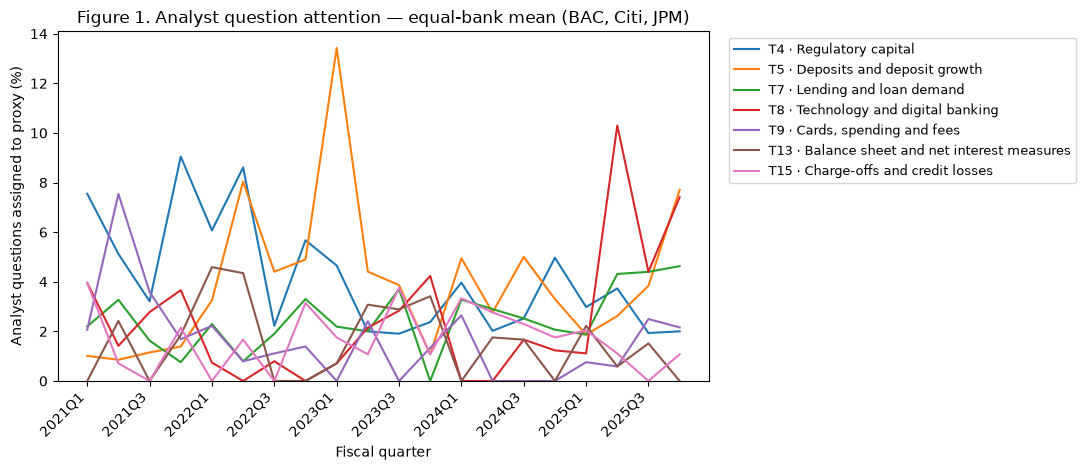

In [ ]:
# Full frozen bank data includes accounting categories, source flags and denominators.
bank_panel = read_csv("stage5_bank_quarter_full.csv")
# Check unique rows and preserve the full denominator.
keys = ["estimand","role","call_id","category_id"]
assert len(bank_panel) == 3120 and not bank_panel.duplicated(keys).any()
assert set(bank_panel.bank_id) == set(BANKS)
assert set(bank_panel.fiscal_period) == set(PERIODS)
assert np.allclose(bank_panel.share, bank_panel.mass/bank_panel.denominator, atol=1e-12, rtol=0)
assert np.allclose(bank_panel.groupby(["estimand","role","call_id"]).share.sum(), 1, atol=1e-12, rtol=0)
retained = bank_panel[bank_panel.category_id.isin(THEMES)].copy()
question_panel = retained[retained.estimand.eq("question_frequency")]
question_denominators = bank_panel[bank_panel.estimand.eq("question_frequency")].groupby("call_id").denominator.first()
assert question_denominators.sum() == 1900
# Equal-bank means; annual contrasts use all four quarters.
quarter_mean = question_panel.groupby(["fiscal_period","category_id"]).share.mean().unstack("category_id").reindex(index=PERIODS,columns=THEMES)
annual = question_panel.groupby(["category_id","year"]).share.mean().unstack("year").loc[THEMES]
bank_annual = question_panel.groupby(["category_id","bank_id","year"]).share.mean().unstack("year")
bank_change = (100*(bank_annual[2025]-bank_annual[2021])).unstack("bank_id").loc[THEMES,BANKS]
annual_display = pd.DataFrame({"Theme":[labels[k] for k in THEMES], "2021 mean (%)":100*annual[2021], "2025 mean (%)":100*annual[2025], "Change (pp)":100*(annual[2025]-annual[2021])}, index=THEMES)
show_table(annual_display.round(2), "Table 6. Annual means of original-denominator question shares.")
show_table(bank_change.rename(index=short_labels).round(2), "Table 7. Same annual change separately for BAC, Citi and JPM (percentage points).")
# Plot equal-bank mean question shares.
fig, ax = plt.subplots(figsize=(11,4.8))
for k in THEMES:
    ax.plot(range(20), 100*quarter_mean[k], label=short_labels[k])
ax.set_xticks(range(0,20,2), PERIODS[::2], rotation=45, ha="right")
ax.set_ylim(bottom=0)
ax.set_ylabel("Analyst questions assigned to proxy (%)")
ax.set_xlabel("Fiscal quarter")
ax.set_title("Figure 1. Analyst question attention — equal-bank mean (BAC, Citi, JPM)")
ax.legend(bbox_to_anchor=(1.02,1), loc="upper left", fontsize=9)
finish_figure(fig, "01_equal_bank_question_attention")


**Finding.** I observe annual increases of 2.91 percentage points for deposits and 1.84 for lending. Both increase in all three banks, but lending changes much more in BAC (+4.20 pp) than JPM (+0.24 pp). Capital and cards decline in every bank. [Tables 6–7]

Technology rises 2.85 pp on average, but the bank changes are **+6.17 pp in BAC, +2.74 pp in Citi and −0.36 pp in JPM**. The average rise combines increases at BAC and Citi with a small decline at JPM. The next table describes the linear component across the full period.


### 3.1 Annual contrasts versus full-period slopes

I also describe each stream with $X_{b,t,k}=\alpha_{b,k}+\lambda_k t+u_{b,t,k}$.

**Spoken:** attention equals a bank-specific baseline plus lambda times the quarter index.

Table 7B gives all seven themes in all three streams, in percentage points per quarter. The saved trend intervals use synchronous residual blocks, 999 attempts and an all-draws-valid rule. Tables 7C–7D show block lengths 2–4 and the fixed bank/quarter/year omissions. Each slope summarises the linear component across all twenty quarters. [S7]


In [ ]:
trend_results=read_csv("stage5_trends_full.csv")
trend_keys=["estimand","role","category_id"]
assert len(trend_results)==651
stream_labels={('question_frequency','analyst'):'Analyst question share',('token_mass','analyst'):'Analyst token share',('token_mass','prepared_management'):'Prepared token share'}

# Preserve withheld intervals; convert units only for display.
def saved_interval(row, multiplier=1):
    if str(row.interval_status).startswith("WITHHELD"):
        assert pd.isna(row.interval_low) and pd.isna(row.interval_high)
        return f"Withheld ({int(row.failed)}/999 failed)"
    assert str(row.interval_status).startswith("VISIBLE")
    assert np.isfinite([row.interval_low,row.interval_high]).all()
    return f"[{multiplier*row.interval_low:+.3f}, {multiplier*row.interval_high:+.3f}]"

# All seven themes × three streams.
trend_primary=trend_results[trend_results.sensitivity.eq("full")].copy()
assert len(trend_primary)==21 and not trend_primary.duplicated(trend_keys).any()
trend_primary["Stream"]=[stream_labels[(e,r)] for e,r in zip(trend_primary.estimand,trend_primary.role)]
trend_primary["Slope and interval (pp/quarter)"]=trend_primary.apply(lambda r:f"{100*r.point:+.3f}  {saved_interval(r,100)}",axis=1)
trend_matrix=trend_primary.pivot(index="category_id",columns="Stream",values="Slope and interval (pp/quarter)").reindex(THEMES).rename(index=short_labels)
show_table(trend_matrix,"Table 7B. All 21 fixed primary linear-trend descriptions; 60 bank-quarter rows / 20 quarters each.")
# Compare uncertainty at the three saved block lengths.
trend_blocks=trend_results[trend_results.attempted.gt(0)].copy()
assert len(trend_blocks)==63
trend_blocks["Stream"]=[stream_labels[(e,r)] for e,r in zip(trend_blocks.estimand,trend_blocks.role)]
trend_blocks["Interval (pp/quarter)"]=trend_blocks.apply(lambda r:saved_interval(r,100),axis=1)
trend_block_table=trend_blocks.pivot(index=["category_id","Stream"],columns="block_length",values="Interval (pp/quarter)").reindex(columns=[2,3,4])
show_table(trend_block_table,"Table 7C. Trend intervals by block length: 21 theme/stream combinations × 3 lengths.")
# Summarise all saved leave-out estimates.
trend_omissions=trend_results[trend_results.sensitivity.str.startswith("leave_one_")].copy()
trend_omissions["Stream"]=[stream_labels[(e,r)] for e,r in zip(trend_omissions.estimand,trend_omissions.role)]
omit_summary=trend_omissions.groupby(["category_id","Stream","sensitivity"]).point.agg(['size','min','max'])
omit_summary["Range (pp/quarter)"]=omit_summary.apply(lambda r:f"{100*r['min']:+.3f} to {100*r['max']:+.3f} (n={int(r['size'])})",axis=1)
show_table(omit_summary['Range (pp/quarter)'].unstack('sensitivity'),"Table 7D. Point-estimate ranges: 3 bank, 20 quarter and 5 year omissions per theme/stream.")


Stream,Analyst question share,Analyst token share,Prepared token share
category_id,,,
T4 · Regulatory capital,"-0.237 [-0.381, -0.109]","-0.266 [-0.395, -0.149]","-0.020 [-0.152, +0.108]"
T5 · Deposits and deposit growth,"+0.098 [-0.143, +0.352]","+0.146 [-0.082, +0.362]","-0.101 [-0.247, +0.038]"
T7 · Lending and loan demand,"+0.102 [+0.031, +0.172]","+0.079 [-0.004, +0.164]","-0.112 [-0.236, +0.008]"
T8 · Technology and digital banking,"+0.167 [-0.039, +0.369]","+0.174 [-0.113, +0.471]","+0.067 [-0.104, +0.247]"
"T9 · Cards, spending and fees","-0.130 [-0.239, -0.006]","-0.107 [-0.303, +0.133]","-0.057 [-0.123, +0.006]"
T13 · Balance sheet and net interest measures,"-0.042 [-0.152, +0.067]","-0.050 [-0.139, +0.046]","+0.048 [-0.018, +0.110]"
T15 · Charge-offs and credit losses,"-0.004 [-0.091, +0.082]","-0.030 [-0.111, +0.055]","+0.060 [-0.031, +0.145]"


Table 7B. All 21 fixed primary linear-trend descriptions; 60 bank-quarter rows / 20 quarters each.


Table 7C. Trend intervals by block length: 21 theme/stream combinations × 3 lengths.


Table 7D. Point-estimate ranges: 3 bank, 20 quarter and 5 year omissions per theme/stream.


**Evaluation.** For analyst question frequency, I find a negative capital slope (−0.237 pp/quarter; interval [−0.381, −0.109]), a positive lending slope (+0.102; [0.031, 0.172]) and a negative cards slope (−0.130; [−0.238, −0.006]). Deposits and technology have positive annual contrasts, but their slope intervals include zero. The analyst-token lending interval also includes zero. [Tables 7B–7D]

The annual rises in deposits and technology coexist with slope intervals spanning both signs. The lending slope also differs in precision between question and token shares. All reported intervals are individual, unadjusted summaries conditional on the fixed topic measurement.


## 4 RQ2 — analysts versus the same bank's prepared remarks

I match **bank, call, quarter and theme**, using token shares for both roles:

$$A_{b,t,k}=\frac{\text{analyst content tokens assigned to }k}{\text{all analyst content tokens}},\quad M_{b,t,k}=\frac{\text{prepared tokens assigned to }k}{\text{all prepared-management content tokens}},$$
$$G_{b,t,k}=100(A_{b,t,k}-M_{b,t,k}).$$

**Spoken:** the gap is one hundred times analyst token share minus prepared-management token share. Positive means a higher analyst share; negative means a higher prepared-management share.

Each share uses its role's total content tokens as the denominator. The gap measures the difference in the two roles' proportional emphasis on the same proxy. [S2]


In [ ]:
# Match bank + call + quarter + theme.
join_keys = ["bank_id","call_id","fiscal_period","t","category_id"]
tokens = retained[retained.estimand.eq("token_mass")]
analyst_tokens = tokens[tokens.role.eq("analyst")][join_keys+["share","mass","denominator"]].rename(columns={"share":"A","mass":"A_mass","denominator":"A_denominator"})
management_tokens = tokens[tokens.role.eq("prepared_management")][join_keys+["share","mass","denominator"]].rename(columns={"share":"M","mass":"M_mass","denominator":"M_denominator"})
# Outer join exposes any unmatched role rows.
paired = analyst_tokens.merge(management_tokens, on=join_keys, how="outer", validate="one_to_one", indicator=True)
assert paired._merge.eq("both").all() and len(paired)==420
paired = paired.drop(columns="_merge")
assert paired.groupby(["bank_id","category_id"]).size().eq(20).all()
# Signed difference on each role's original token denominator.
paired["gap_pp"] = 100*(paired.A-paired.M)
mean_gap = paired.groupby(["category_id","bank_id"]).gap_pp.mean().unstack().loc[THEMES,BANKS]
show_table(mean_gap.rename(index=short_labels).round(2),
           "Table 8. Mean same-call analyst minus prepared-management token share, over 20 quarters (pp).")
print("420 matched same-bank pairs: 3 banks × 20 quarters × 7 themes.")


bank_id,BAC,CITI,JPM
category_id,,,
T4 · Regulatory capital,2.68,0.52,4.09
T5 · Deposits and deposit growth,0.19,1.20,1.00
T7 · Lending and loan demand,-0.56,-1.05,1.33
T8 · Technology and digital banking,0.16,-1.33,3.84
"T9 · Cards, spending and fees",0.25,-2.88,1.75
T13 · Balance sheet and net interest measures,2.24,0.16,-0.10
T15 · Charge-offs and credit losses,-0.84,1.85,-1.97


Table 8. Mean same-call analyst minus prepared-management token share, over 20 quarters (pp).
420 matched same-bank pairs: 3 banks × 20 quarters × 7 themes.


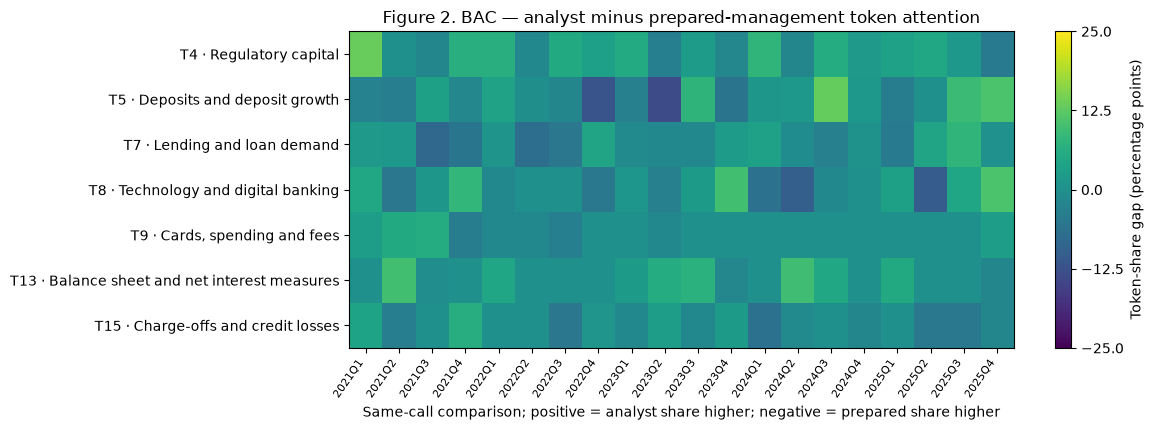

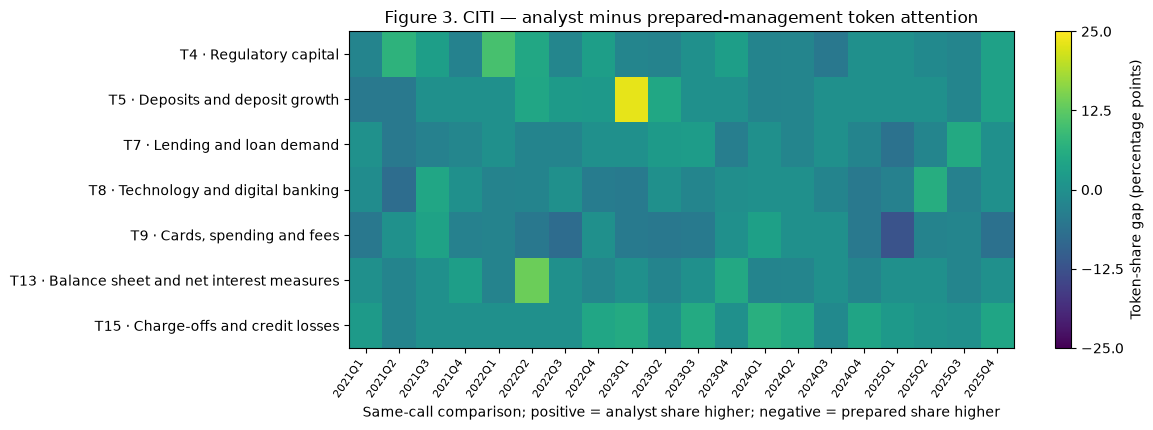

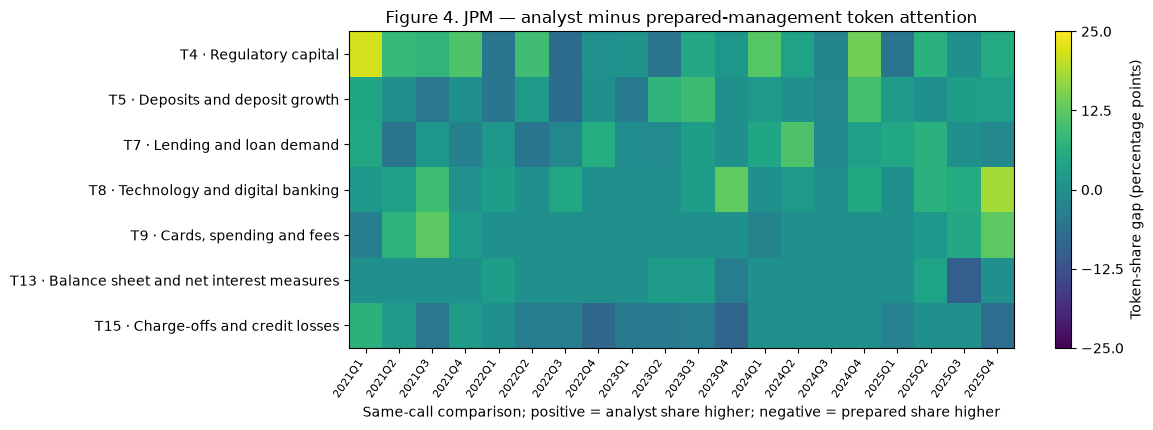

In [ ]:
# Each bank gets its own figure. Identical order, quarter grid and colour scale aid comparison.
# Signed difference; zero is the scale midpoint.
gap_limit = float(np.ceil(paired.gap_pp.abs().max()/5)*5)
for number, bank in enumerate(BANKS, start=2):
    grid = paired[paired.bank_id.eq(bank)].pivot(index="category_id",columns="fiscal_period",values="gap_pp").reindex(index=THEMES,columns=PERIODS)
    assert not grid.isna().any().any()
    fig, ax = plt.subplots(figsize=(12,4.4))
    image = ax.imshow(grid.to_numpy(), aspect="auto", vmin=-gap_limit, vmax=gap_limit)
    ax.set_yticks(range(7),[short_labels[k] for k in THEMES])
    ax.set_xticks(range(20),PERIODS,rotation=55,ha="right",fontsize=8)
    ax.set_title(f"Figure {number}. {bank} — analyst minus prepared-management token attention")
    ax.set_xlabel("Same-call comparison; positive = analyst share higher; negative = prepared share higher")
    fig.colorbar(image,ax=ax,label="Token-share gap (percentage points)",ticks=[-gap_limit,-gap_limit/2,0,gap_limit/2,gap_limit])
    finish_figure(fig,f"{number:02d}_same_call_gaps_{bank}")


**Finding.** Mean lending gaps are **−0.56 pp in BAC, −1.05 pp in Citi and +1.33 pp in JPM**. Technology gaps are +0.16, −1.33 and +3.84 pp respectively. The signs differ across banks. [Table 8]

Figures 2–4 show every theme and quarter on the same gap scale. Figures 5–7 show the two underlying T7 trajectories. I use T7 to illustrate the timing result discussed below; the all-theme tables and maps remain visible. `plot_same_bank_topic(bank, theme)` can display any fixed theme.


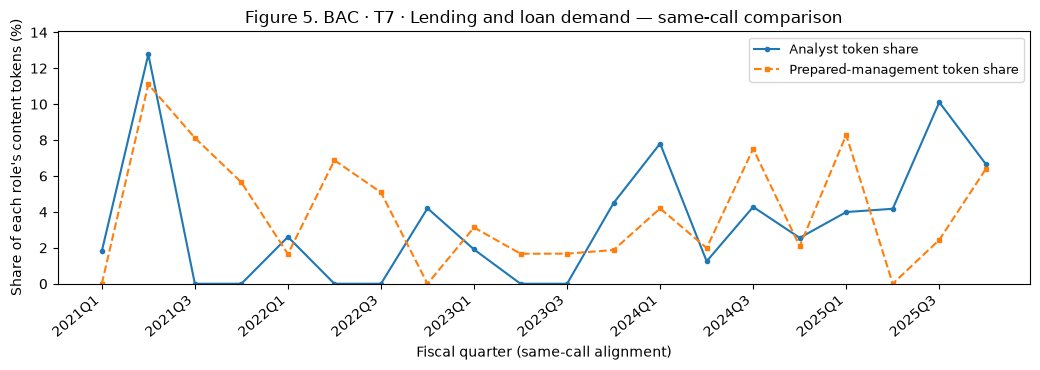

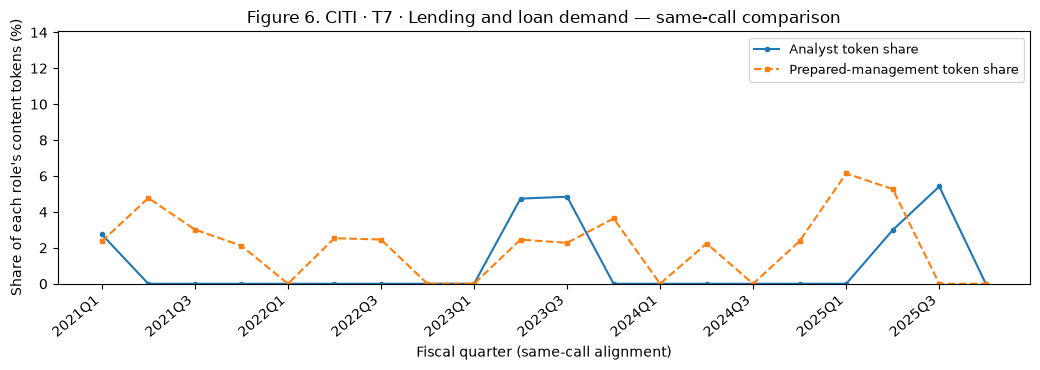

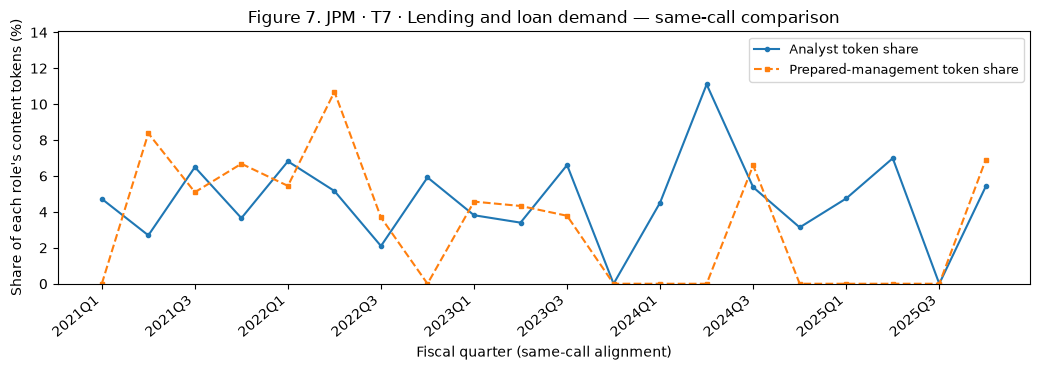

In [ ]:
def plot_same_bank_topic(bank, theme, figure_number=None):
    if bank not in BANKS or theme not in THEMES:
        raise ValueError("Use a registered bank and fixed theme.")
    # Align the same bank's two roles to the complete quarter grid.
    z = paired[paired.bank_id.eq(bank)&paired.category_id.eq(theme)].set_index("fiscal_period").reindex(PERIODS)
    if z[["A","M"]].isna().any().any():
        raise ValueError("Missing same-bank pairs must not be filled with zero.")
    # Same y-range across all banks for the chosen theme.
    all_banks = paired[paired.category_id.eq(theme)]
    ymax = max(1.0, float(100*all_banks[["A","M"]].to_numpy().max())*1.1)
    fig, ax = plt.subplots(figsize=(10.5,3.8))
    ax.plot(range(20),100*z.A,linestyle="-",marker="o",markersize=3,label="Analyst token share")
    ax.plot(range(20),100*z.M,linestyle="--",marker="s",markersize=3,label="Prepared-management token share")
    ax.set_ylim(0,ymax)
    ax.set_xticks(range(0,20,2),PERIODS[::2],rotation=40,ha="right")
    prefix=f"Figure {figure_number}. " if figure_number else ""
    ax.set_title(f"{prefix}{bank} · {short_labels[theme]} — same-call comparison")
    ax.set_ylabel("Share of each role's content tokens (%)")
    ax.set_xlabel("Fiscal quarter (same-call alignment)")
    ax.legend(loc="upper right",fontsize=9)
    finish_figure(fig,f"paired_{bank}_{theme}")

# T7 is the displayed example; the helper supports every fixed theme.
EXAMPLE_THEME = "T7"
for number, bank in enumerate(BANKS,start=5):
    plot_same_bank_topic(bank,EXAMPLE_THEME,number)


**Evaluation.** Table 8 shows a negative average lending gap for BAC and Citi and a positive gap for JPM. Figures 5–7 show the corresponding same-call token-share paths. Their peaks, troughs and zero-assignment quarters differ across banks. A zero is the frozen transform's recorded assignment of zero token mass to T7.


## 5 Common versus bank-relative variation

I split each series into its three-bank quarter mean and the bank's deviation:

$$X_{b,t}=\bar X_t+(X_{b,t}-\bar X_t),$$
$$SS_{total}=\sum_{b,t}(X_{b,t}-\bar X)^2=3\sum_t(\bar X_t-\bar X)^2+\sum_{b,t}(X_{b,t}-\bar X_t)^2.$$

**Spoken:** total centred variation equals common-quarter variation plus bank-relative variation. The common fraction is common sum of squares divided by total sum of squares.

The relative component combines persistent bank differences with quarter-specific deviations from the three-bank mean. [S2]


In [ ]:
decomposition = read_csv("stage5_decomposition_summary.csv")
# Reshape the two separately measured streams for comparison.
display_decomp = decomposition.assign(common_pct=100*decomposition.common_fraction).pivot(index="category_id",columns="role",values="common_pct").loc[THEMES]
display_decomp = display_decomp.rename(index=short_labels,columns={"analyst":"Analyst question-frequency common fraction (%)","prepared_management":"Prepared-token common fraction (%)"})
show_table(display_decomp.round(1), "Table 9. Common-quarter fractions for question and prepared-token shares.")


role,Analyst question-frequency common fraction (%),Prepared-token common fraction (%)
category_id,,
T4 · Regulatory capital,36.9,37.9
T5 · Deposits and deposit growth,33.1,20.6
T7 · Lending and loan demand,23.3,49.6
T8 · Technology and digital banking,53.8,29.7
"T9 · Cards, spending and fees",51.3,23.8
T13 · Balance sheet and net interest measures,32.2,33.8
T15 · Charge-offs and credit losses,25.2,18.5


Table 9. Common-quarter fractions for question and prepared-token shares.


**Finding.** Common-quarter variation accounts for 23.3–53.8% of analyst question-share variation and 18.5–49.6% of prepared-token variation. The remaining variation lies in the bank-relative component. Both components contribute across the seven themes. [Table 9]


## 6 Coverage and accounting

I sum the seven proxy shares on each original denominator. Table 10 gives coverage by bank and stream; Table 10B gives the equal-bank quarterly ranges. Table 11 retains the separate unresolved, conversational, noise and not-fitted outcomes. [S2]


In [ ]:
# Sum retained themes first, within each call and stream.
coverage_by_call = retained.groupby(["estimand","role","bank_id","call_id","fiscal_period"]).share.sum().rename("retained_share").reset_index()
coverage_table = 100*coverage_by_call.groupby(["estimand","role","bank_id"]).retained_share.agg(["min","mean","max"])
show_table(coverage_table.round(1), "Table 10. Retained coverage (%) — bank-specific ranges across 20 quarters.")
# Equal-bank quarterly means are a different aggregation from per-bank ranges.
coverage_quarter = coverage_by_call.groupby(["estimand", "role", "fiscal_period"]).retained_share.mean()
coverage_equal_bank = 100 * coverage_quarter.groupby(["estimand", "role"]).agg(["min", "mean", "max"])
show_table(coverage_equal_bank.round(1), "Table 10B. Retained coverage (%) — equal-bank quarterly ranges.")
# Display roll-up only; original source buckets remain unchanged.
accounting_rollup = bank_panel.assign(display_category=np.where(bank_panel.included_in_theme_analysis,"RETAINED",bank_panel.action)).groupby(["estimand","role","bank_id","call_id","fiscal_period","display_category"]).share.sum().unstack("display_category",fill_value=0)
assert np.allclose(accounting_rollup.sum(axis=1),1,atol=1e-12,rtol=0)
accounting_summary = 100*accounting_rollup.groupby(["estimand","role"]).mean()
show_table(accounting_summary.round(2), "Table 11. Equal-call mean accounting across 60 calls; each row totals 100%.")


Table 10. Retained coverage (%) — bank-specific ranges across 20 quarters.


Table 10B. Retained coverage (%) — equal-bank quarterly ranges.


Table 11. Equal-call mean accounting across 60 calls; each row totals 100%.


**Evaluation.** Equal-bank quarterly coverage is 10.4–25.0% of analyst questions, 8.8–31.3% of analyst tokens and 7.5–21.8% of prepared tokens. Individual-bank ranges differ. [Tables 10–10B]

The retained shares measure seven narrow themes; Table 11 allocates the remainder to the four accounting categories. All analyst text can enter token projection even when its parent question was excluded from primary fitting; `NOT_FITTED` question status and token-projection coverage are therefore different concepts.


## 7 RQ3 — lead–lag structure over 0–4 quarters

I separate the descriptive grid from the conditional model:

1. **Descriptive:** $h=0,1,2,3,4$, both directions, using levels, first differences, bank-relative series and the common three-bank path.
2. **Conditional:** the separately fixed **h=1**, analyst-to-prepared-management regression family. Controlled coefficients and bootstrap intervals are available for this direction and horizon.

$$r^{A\to M}_k(h)=\operatorname{Corr}(A_{b,t,k},M_{b,t+h,k}),\qquad r^{M\to A}_k(h)=\operatorname{Corr}(M_{b,t,k},A_{b,t+h,k}).$$

**Spoken:** forward correlation compares analyst attention now with prepared attention h quarters later; reverse correlation exchanges the roles.

Except for the labelled common-path diagnostic, I match within bank before pooling the token-share pairs. At h=0 the directions are identical. At h=4 the pooled level comparison has 48 rows but only 16 temporal origins; first differences lose another origin. The join requires the stated calendar-quarter separation. [S3]


In [ ]:
lag_results=read_csv("stage5_lag_results_full.csv")
MODES=["level_pooled","first_difference","bank_relative","common_three_bank"]
mode_labels={"level_pooled":"Same-bank paired levels (pooled rows)","first_difference":"Same-bank paired first differences","bank_relative":"Same-bank deviations from quarterly bank mean","common_three_bank":"Three-bank average paths"}
lag_keys=["category_id","direction","mode","lag"]
# Require the complete fixed theme/direction/mode/horizon grid.
expected=pd.MultiIndex.from_product([THEMES,["forward","reverse"],MODES+["equal_parent_sensitivity"],range(5)],names=lag_keys)
actual=pd.MultiIndex.from_frame(lag_results[lag_keys])
assert len(lag_results)==350 and not actual.has_duplicates and set(actual)==set(expected)
# Preserve the recorded missing-value status.
undefined=lag_results[lag_results["mode"].eq("equal_parent_sensitivity")]
assert len(undefined)==70 and undefined.correlation.isna().all()
assert undefined.status.eq("NOT_AVAILABLE_NONADDITIVE_BRIDGE_INPUTS").all()
assert undefined.n_pairs.eq(0).all()
lag_defined=lag_results[lag_results["mode"].isin(MODES)].copy()
assert len(lag_defined)==280 and lag_defined.status.eq("OK").all()
assert np.isfinite(lag_defined.correlation).all()

# Count origins and matched rows at each horizon.
support_rows=[]
for mode in MODES:
    for h in range(5):
        subset=lag_defined[lag_defined["mode"].eq(mode)&lag_defined.lag.eq(h)]
        n_origins=20-h-(mode=='first_difference')
        n_pairs=n_origins*(1 if mode=='common_three_bank' else 3)
        assert subset.calendar_origins.eq(n_origins).all() and subset.n_pairs.eq(n_pairs).all()
        support_rows.append({'Representation':mode_labels[mode],'h':h,'Support':f'{n_pairs} rows / {n_origins} origins'})
show_table(pd.DataFrame(support_rows).pivot(index='Representation',columns='h',values='Support').reindex([mode_labels[m] for m in MODES]),"Table 12A. Matched rows and temporal origins by representation and horizon.")
# Print all four complete correlation matrices.
lag_matrices={}
for letter,mode in zip('BCDE',MODES):
    grid=lag_defined[lag_defined['mode'].eq(mode)].pivot(index='category_id',columns=['direction','lag'],values='correlation')
    columns=pd.MultiIndex.from_product([['forward','reverse'],range(5)],names=['Direction','h'])
    grid=grid.reindex(index=THEMES,columns=columns)
    assert not grid.isna().any().any()
    assert np.allclose(grid[('forward',0)],grid[('reverse',0)],atol=1e-12,rtol=0)
    lag_matrices[mode]=grid
    show_table(grid.rename(index=short_labels).round(3),f'Table 12{letter}. {mode_labels[mode]}: Pearson correlations for all themes, both directions and h=0–4.')
show_table(pd.DataFrame([{'Representation':'Equal-parent sensitivity','Rows':70,'Horizons':'0–4; both directions; all themes','Result':'Unavailable: required non-additive inputs absent'}]),"Table 12F. Unavailable equal-parent sensitivity.")


h,0,1,2,3,4
Representation,,,,,
Same-bank paired levels (pooled rows),60 rows / 20 origins,57 rows / 19 origins,54 rows / 18 origins,51 rows / 17 origins,48 rows / 16 origins
Same-bank paired first differences,57 rows / 19 origins,54 rows / 18 origins,51 rows / 17 origins,48 rows / 16 origins,45 rows / 15 origins
Same-bank deviations from quarterly bank mean,60 rows / 20 origins,57 rows / 19 origins,54 rows / 18 origins,51 rows / 17 origins,48 rows / 16 origins
Three-bank average paths,20 rows / 20 origins,19 rows / 19 origins,18 rows / 18 origins,17 rows / 17 origins,16 rows / 16 origins


Table 12A. Matched rows and temporal origins by representation and horizon.


Table 12B. Same-bank paired levels (pooled rows): Pearson correlations for all themes, both directions and h=0–4.


Table 12C. Same-bank paired first differences: Pearson correlations for all themes, both directions and h=0–4.


Table 12D. Same-bank deviations from quarterly bank mean: Pearson correlations for all themes, both directions and h=0–4.


Table 12E. Three-bank average paths: Pearson correlations for all themes, both directions and h=0–4.


,Representation,Rows,Horizons,Result
0,Equal-parent sensitivity,70,0–4; both directions; all themes,Unavailable: required non-additive inputs absent


Table 12F. Unavailable equal-parent sensitivity.


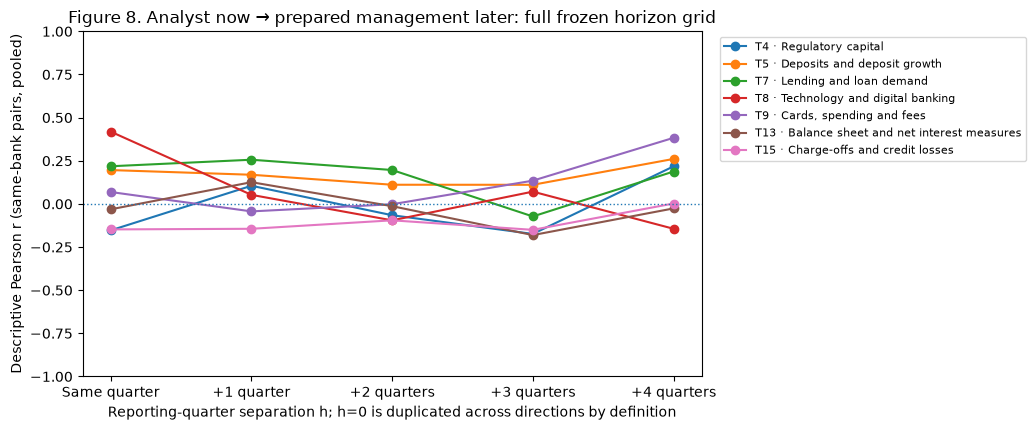

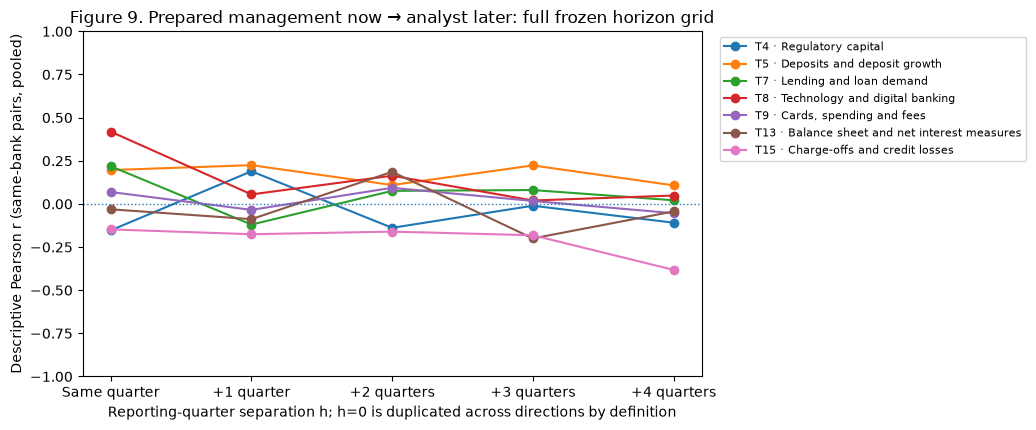

In [ ]:
# Plot the forward/reverse level grids; other modes are in Tables 12C–12E.
for number,direction in [(8,'forward'),(9,'reverse')]:
    grid=lag_matrices['level_pooled'][direction]
    fig,ax=plt.subplots(figsize=(10.5,4.4))
    for k in THEMES:
        ax.plot(range(5),grid.loc[k].to_numpy(),marker='o',label=short_labels[k])
    ax.axhline(0,linestyle=':',linewidth=1)
    ax.set_xticks(range(5),['Same quarter','+1 quarter','+2 quarters','+3 quarters','+4 quarters'])
    ax.set_ylim(-1,1)
    ax.set_ylabel('Descriptive Pearson r (same-bank pairs, pooled)')
    ax.set_xlabel('Reporting-quarter separation h; h=0 is duplicated across directions by definition')
    label='Analyst now → prepared management later' if direction=='forward' else 'Prepared management now → analyst later'
    ax.set_title(f'Figure {number}. {label}: full frozen horizon grid')
    ax.legend(bbox_to_anchor=(1.02,1),loc='upper left',fontsize=8)
    finish_figure(fig,f'{number:02d}_lag_grid_{direction}')


### 7.1 Evaluation of the full grid

For **T7**, forward level correlations at h=0–4 are 0.218, 0.256, 0.196, −0.073 and 0.188; reverse h=1 is −0.120. Forward h=1 falls to 0.119 in first differences. At h=4, the common-path value is 0.516 and the bank-relative value is 0.087. The longer-horizon association is stronger in the common average than in the deviations around it. [Tables 12B–12E; Figures 8–9]

At h=4, T5 is 0.261 in levels and 0.370 bank-relative. T9 is 0.383 in levels, 0.460 in differences, 0.389 bank-relative and 0.501 in the common path; its reverse level value is −0.054. These are the descriptive longer-horizon correlations available in the saved grid.

T8's same-call correlation of 0.419 falls to 0.053 at forward h=1. T5's reverse h=1 correlation of 0.225 exceeds its forward value of 0.169. The size and direction of the associations vary across themes, horizons and representations.

The grid contains 280 defined, correlated comparisons, including duplicate h=0 directions. At h=4 the level estimates use 16 temporal origins. Section 9A reports the associated within-series persistence, and the next section shows the separately fixed h=1 conditional estimates.


### 7.2 Fixed +1 conditional model

$$M_{b,t+1,k}=\alpha_{b,k}+\rho_k M_{b,t,k}+\gamma_k t+\beta_k A_{b,t,k}+\varepsilon_{b,t+1,k}.$$

**Spoken:** next-quarter prepared attention equals a bank-specific intercept, current prepared attention, a time trend and beta times current analyst attention.

I estimate **one shared slope per theme** from matched same-bank pairs, with bank-specific intercepts. The baseline uses 57 rows / 19 origins; first differences use 54 / 18. The intercepts account for average level differences between the banks. [S3]


In [ ]:
# Keep origin and target IDs so the lag join is auditable.
origin = paired[["bank_id","call_id","fiscal_period","t","category_id","A","M"]].copy()
target = paired[["bank_id","call_id","fiscal_period","t","category_id","M"]].rename(columns={"call_id":"target_call_id","fiscal_period":"target_period","M":"next_M"})
target["target_bank_id"] = target.bank_id
target["target_t"] = target.t
# Shift the target key back one quarter to match each origin.
target["t"] -= 1
# Same-bank h=1 join; verify exact calendar adjacency.
next_pairs = origin.merge(target,on=["bank_id","t","category_id"],validate="one_to_one")
assert len(next_pairs)==399  # Seven themes × 57 same-bank pairs.
assert next_pairs.bank_id.eq(next_pairs.target_bank_id).all()
assert next_pairs.target_t.eq(next_pairs.t+1).all()
assert next_pairs.groupby("category_id").size().eq(57).all()
example = next_pairs[next_pairs.category_id.eq("T7")].sort_values(["bank_id","t"]).groupby("bank_id",sort=False).head(2)
show_table(example[["bank_id","call_id","target_call_id","fiscal_period","target_period"]].reset_index(drop=True),
           "Table 13. Same-bank +1 matching example for T7.")


,bank_id,call_id,target_call_id,fiscal_period,target_period
0,BAC,BAC_2021Q1_earnings_call,BAC_2021Q2_earnings_call,2021Q1,2021Q2
1,BAC,BAC_2021Q2_earnings_call,BAC_2021Q3_earnings_call,2021Q2,2021Q3
2,CITI,CITI_2021Q1_earnings_call,CITI_2021Q2_earnings_call,2021Q1,2021Q2
3,CITI,CITI_2021Q2_earnings_call,CITI_2021Q3_earnings_call,2021Q2,2021Q3
4,JPM,JPM_2021Q1_earnings_call,JPM_2021Q2_earnings_call,2021Q1,2021Q2
5,JPM,JPM_2021Q2_earnings_call,JPM_2021Q3_earnings_call,2021Q2,2021Q3


Table 13. Same-bank +1 matching example for T7.


### 7.3 Specifications and uncertainty

I compare levels, first differences, bank-relative shares, origin-quarter coverage controls and quarter-of-year controls. The complete family shows how the estimated relationship changes with each adjustment.

The saved intervals use paired, noncircular blocks of complete origins: 999 attempts, seed 17029, length 3 primary and lengths 2/4 for baseline sensitivity. Banks from the same origin stay together. An interval is shown only if all 999 draws succeed and original support is sufficient. Every failed draw remains in the attempt count. The displayed limits are individual percentile summaries conditional on the fixed measurement. [S3]


In [ ]:
plus1_results = read_csv("stage5_plus1_full.csv")
VARIANTS=["baseline","first_difference","bank_relative","coverage_controls","seasonality"]
variant_labels={"baseline":"Levels","first_difference":"First differences","bank_relative":"Bank-relative","coverage_controls":"Coverage controls","seasonality":"Seasonality"}
# Primary block length, all five specifications.
family = plus1_results[plus1_results.block_length.eq(3)].copy()
assert len(family)==35 and not family.duplicated(["category_id","variant"]).any()

# Validate status before formatting interval endpoints.
def interval_text(row, low="interval_low", high="interval_high"):
    if str(row.interval_status).startswith("WITHHELD"):
        if pd.notna(row[low]) or pd.notna(row[high]):
            raise ValueError("A withheld interval must remain unavailable.")
        return f"Withheld ({int(row.failed)}/999 failed)"
    if not np.isfinite([row[low],row[high]]).all():
        raise ValueError("Visible interval has missing endpoints.")
    return f"[{row[low]:+.3f}, {row[high]:+.3f}]"

family["interval"] = family.apply(interval_text,axis=1)
# Baseline first, then the full sensitivity family.
base = family[family.variant.eq("baseline")].set_index("category_id").loc[THEMES]
base_view=base[["point","interval","rows","origins","valid","failed"]].rename(index=short_labels,columns={"point":"Beta (pp/pp)"})
show_table(base_view.round(3), "Table 14. Baseline shared slopes and descriptive intervals.")
family["estimate_and_interval"] = family.apply(lambda r:f"{r.point:+.3f}  {r['interval']}",axis=1)
full_family=family.pivot(index="category_id",columns="variant",values="estimate_and_interval").reindex(index=THEMES,columns=VARIANTS).rename(index=short_labels,columns=variant_labels)
show_table(full_family, "Table 15. All 35 block-3 estimates. Differences: 54 rows / 18 origins; other variants: 57 / 19.")


,Beta (pp/pp),interval,rows,origins,valid,failed
category_id,,,,,,
T4 · Regulatory capital,0.053,"[-0.137, +0.271]",57,19,999,0
T5 · Deposits and deposit growth,-0.002,"[-0.127, +0.158]",57,19,999,0
T7 · Lending and loan demand,0.259,"[+0.041, +0.631]",57,19,999,0
T8 · Technology and digital banking,0.131,"[-0.088, +0.510]",57,19,999,0
"T9 · Cards, spending and fees",-0.114,Withheld (7/999 failed),57,19,992,7
T13 · Balance sheet and net interest measures,0.121,"[-0.044, +0.339]",57,19,999,0
T15 · Charge-offs and credit losses,-0.034,"[-0.239, +0.162]",57,19,999,0


Table 14. Baseline shared slopes and descriptive intervals.


variant,Levels,First differences,Bank-relative,Coverage controls,Seasonality
category_id,,,,,
T4 · Regulatory capital,"+0.053 [-0.137, +0.271]","+0.052 [-0.086, +0.204]","+0.110 [-0.105, +0.285]","+0.093 [-0.130, +0.374]",+0.043 Withheld (1/999 failed)
T5 · Deposits and deposit growth,"-0.002 [-0.127, +0.158]","+0.012 [-0.100, +0.082]","-0.020 [-0.137, +0.143]","+0.016 [-0.165, +0.203]",+0.028 Withheld (1/999 failed)
T7 · Lending and loan demand,"+0.259 [+0.041, +0.631]","+0.167 [-0.010, +0.491]","+0.114 [-0.052, +0.412]","+0.268 [+0.106, +0.625]",+0.241 Withheld (1/999 failed)
T8 · Technology and digital banking,"+0.131 [-0.088, +0.510]","+0.065 [-0.184, +0.380]","+0.333 [-0.189, +1.162]","+0.130 [-0.073, +0.593]",+0.254 Withheld (1/999 failed)
"T9 · Cards, spending and fees",-0.114 Withheld (7/999 failed),-0.068 Withheld (3/999 failed),-0.379 Withheld (7/999 failed),-0.111 Withheld (7/999 failed),-0.081 Withheld (8/999 failed)
T13 · Balance sheet and net interest measures,"+0.121 [-0.044, +0.339]","+0.074 [-0.087, +0.208]","+0.156 [-0.022, +0.399]","+0.096 [-0.094, +0.325]",+0.130 Withheld (1/999 failed)
T15 · Charge-offs and credit losses,"-0.034 [-0.239, +0.162]","-0.036 [-0.226, +0.055]","-0.036 [-0.252, +0.263]","+0.008 [-0.235, +0.199]",-0.018 Withheld (1/999 failed)


Table 15. All 35 block-3 estimates. Differences: 54 rows / 18 origins; other variants: 57 / 19.


In [ ]:
# Same h=1 estimand; compare the three saved block lengths.
timing_blocks=plus1_results[plus1_results.variant.eq('baseline')].copy()
assert len(timing_blocks)==21 and set(timing_blocks.block_length)=={2,3,4}
timing_blocks['Interval']=timing_blocks.apply(interval_text,axis=1)
show_table(timing_blocks.pivot(index='category_id',columns='block_length',values='Interval').reindex(index=THEMES,columns=[2,3,4]).rename(index=short_labels),"Table 15B. Baseline h=1 intervals at block lengths 2, 3 and 4.")


block_length,2,3,4
category_id,,,
T4 · Regulatory capital,"[-0.138, +0.271]","[-0.137, +0.271]","[-0.164, +0.276]"
T5 · Deposits and deposit growth,"[-0.135, +0.201]","[-0.127, +0.158]","[-0.123, +0.130]"
T7 · Lending and loan demand,"[+0.028, +0.568]","[+0.041, +0.631]","[+0.028, +0.639]"
T8 · Technology and digital banking,"[-0.073, +0.529]","[-0.088, +0.510]","[-0.100, +0.449]"
"T9 · Cards, spending and fees",Withheld (2/999 failed),Withheld (7/999 failed),Withheld (10/999 failed)
T13 · Balance sheet and net interest measures,"[-0.027, +0.404]","[-0.044, +0.339]","[-0.058, +0.331]"
T15 · Charge-offs and credit losses,"[-0.235, +0.199]","[-0.239, +0.162]","[-0.251, +0.137]"


Table 15B. Baseline h=1 intervals at block lengths 2, 3 and 4.


**Finding.** T7's baseline slope is 0.259 with interval [0.041, 0.631]: a 1 pp difference in current analyst share is associated with about 0.259 pp in next-quarter prepared share after the fixed controls. The coverage-adjusted interval is also positive. First-difference [−0.010, 0.491] and bank-relative [−0.052, 0.412] intervals span zero; the seasonal interval is withheld after one failed draw. [Tables 14–15B]

T9 has negative point estimates and withheld block-3 intervals across all five variants. The recorded failed-draw counts explain their availability status.

**Answer to RQ3.** Lending has positive baseline and coverage-adjusted h=1 estimates, with weaker precision under differencing and bank-relative adjustment. The evidence for a shared-slope timing association is specification-sensitive.


## 8 RQ4 — attention and subsequent financial growth

I use two fixed question-frequency composites:

$$Q^{NII}_{b,t}=Q_{b,t,T13}+Q_{b,t,T5},\qquad Q^{LDG}_{b,t}=Q_{b,t,T7}+Q_{b,t,T5}.$$

These are unweighted unions of distinct question buckets on the original denominator. Topics 3 and 12 remain unresolved, so the NII/rates/deposits construct is partial. [S4]

$$g_{b,t+1}=100\left(\frac{Y_{b,t+1}}{Y_{b,t}}-1\right),\qquad g_{b,t+1}=\alpha_b+\phi g_{b,t}+\gamma t+\beta(100Q_{b,t})+\varepsilon_{b,t+1}.$$

**Spoken:** next-quarter percentage growth is related to current attention in percentage points, controlling for bank intercepts, current growth and trend.

Strict NII uses BAC/JPM (36 rows / 18 origins); the arithmetic-screened sensitivity adds Citi (54 / 18). Deposits use all three banks (54 / 18). Each origin requires financial observations at t−1, t and t+1. The change variant differences the attention predictor; the relative variant removes same-origin means from response and predictors and omits the raw-level trend.

I fixed these composites before the BERTopic financial fit, but had already explored financial results earlier in the project. I therefore describe this as a fixed-specification retrospective replication. Calls occur within the following reporting quarter, so part of the financial target quarter has elapsed by the call date.


,metric,tier,specification,Banks,Rows,Origins,Beta,Interval,In-sample delta R²
0,total_deposits,STRICT,change,"BAC, CITI, JPM",54,18,-0.011,"[-0.193, +0.056]",0.001
1,total_deposits,STRICT,level,"BAC, CITI, JPM",54,18,-0.088,"[-0.344, +0.007]",0.038
2,total_deposits,STRICT,relative,"BAC, CITI, JPM",54,18,-0.001,"[-0.164, +0.197]",0.000
3,net_interest_income,ARITHMETIC_SENSITIVITY,level,"BAC, CITI, JPM",54,18,0.082,"[-0.080, +0.242]",0.012
4,net_interest_income,STRICT,change,"BAC, JPM",36,18,0.088,"[-0.122, +0.308]",0.013
5,net_interest_income,STRICT,level,"BAC, JPM",36,18,0.185,"[-0.168, +0.625]",0.024
6,net_interest_income,STRICT,relative,"BAC, JPM",36,18,-0.064,"[-0.578, +0.265]",0.008


Table 16. Financial estimates, bank cohorts and block-3 intervals; variant definitions are above.


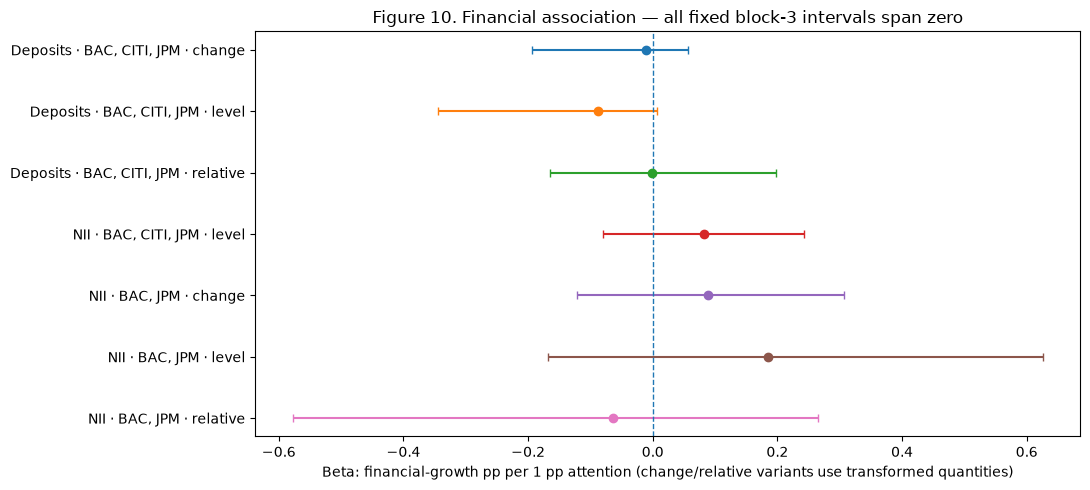

,metric,tier,omission_kind,checks,min_beta,max_beta
0,total_deposits,STRICT,bank,3,-0.101,-0.083
1,total_deposits,STRICT,quarter,18,-0.168,-0.071
2,net_interest_income,ARITHMETIC_SENSITIVITY,bank,3,0.055,0.185
3,net_interest_income,ARITHMETIC_SENSITIVITY,quarter,18,0.057,0.106
4,net_interest_income,STRICT,bank,2,0.163,0.353
5,net_interest_income,STRICT,quarter,18,0.074,0.265


Table 17. Leave-one-bank/origin level-estimate ranges.


In [ ]:
financial_effects=read_csv("stage6_effects.csv")
financial_bootstrap=read_csv("stage6_bootstrap.csv")
financial_leaveout=read_csv("stage6_leaveout_summary.csv")
financial_review=read_json("stage6_direct_review.json")
# Pair each saved estimate with its matching uncertainty record.
keys6=["construct_id","metric","tier","specification"]
assert not financial_effects.duplicated(keys6).any()
b3=financial_bootstrap[financial_bootstrap.block_length.eq(3)]
assert not b3.duplicated(keys6).any()
financial=financial_effects.merge(b3,on=keys6,how="outer",validate="one_to_one",indicator=True)
assert financial._merge.eq("both").all() and len(financial)==7
# Show actual bank cohorts, including the stricter NII sample.
financial["Banks"] = financial.banks.map(lambda x:", ".join(json.loads(x)))
financial["Interval"] = financial.apply(lambda r:f"[{r.ci_low:+.3f}, {r.ci_high:+.3f}]",axis=1)
show_table(financial[["metric","tier","specification","Banks","n","origins","beta","Interval","delta_r2_in_sample"]].rename(columns={"n":"Rows","origins":"Origins","beta":"Beta","delta_r2_in_sample":"In-sample delta R²"}).round(3),
           "Table 16. Financial estimates, bank cohorts and block-3 intervals; variant definitions are above.")

# Plot every fixed financial specification.
plot_data=financial.reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11,5))
for pos,row in plot_data.iterrows():
    ax.errorbar(row.beta,pos,xerr=[[row.beta-row.ci_low],[row.ci_high-row.beta]],fmt="o",capsize=3)
ax.axvline(0,linestyle="--",linewidth=1)
metric_labels={"net_interest_income":"NII", "total_deposits":"Deposits"}
plot_labels=[f"{metric_labels[row.metric]} · {row.Banks} · {row.specification}" for row in plot_data.itertuples()]
ax.set_yticks(range(7),plot_labels)
ax.invert_yaxis()
ax.set_title("Figure 10. Financial association — all fixed block-3 intervals span zero")
ax.set_xlabel("Beta: financial-growth pp per 1 pp attention (change/relative variants use transformed quantities)")
finish_figure(fig,"10_financial_fixed_family")
# Show the range of saved leave-out point estimates.
show_table(financial_leaveout[["metric","tier","omission_kind","checks","min_beta","max_beta"]].round(3),
           "Table 17. Leave-one-bank/origin level-estimate ranges.")


In [ ]:
# Complete raw-level h=1 block-length family.
financial_blocks=financial_bootstrap[financial_bootstrap.specification.eq('level')].copy()
assert len(financial_blocks)==9 and set(financial_blocks.block_length)=={2,3,4}
assert financial_blocks.valid.add(financial_blocks.invalid).eq(financial_blocks.replicates).all()
financial_blocks['Interval']=financial_blocks.apply(lambda r:f'[{r.ci_low:+.3f}, {r.ci_high:+.3f}] ({int(r.valid)}/{int(r.replicates)} valid)',axis=1)
show_table(financial_blocks.pivot(index=['metric','tier'],columns='block_length',values='Interval').reindex(columns=[2,3,4]),"Table 17B. Raw-level h=1 financial intervals at block lengths 2, 3 and 4.")


Table 17B. Raw-level h=1 financial intervals at block lengths 2, 3 and 4.


**Finding.** Strict NII has beta +0.185, interval [−0.168, +0.625]; strict deposits has beta −0.088, interval [−0.344, +0.007]. All seven block-3 intervals span zero, as do the saved block-2/4 level intervals. [Tables 16–17B; Figure 10]

The deposit level estimate stays negative in every bank/origin omission. Its change and relative estimates lie closer to zero, while NII changes sign across specifications. The pattern combines a stable negative deposit level estimate with broad interval uncertainty and sensitivity to transformation.

Stage 6 uses its original 95%-valid interval rule; all 12,987 attempts were valid. Stage 5 retains its separate all-999-valid rule.

**Answer to RQ4.** Both financial families remain inconclusive in this sample: their reported intervals accommodate positive and negative associations.


## 9 Supporting diagnostics



### 9.1 Autocorrelation

I compare each series with its own past using the saved full-path-centred convention:

$$ACF_X(h)=\frac{\sum_{t:t-h\ \mathrm{exists}}(X_t-\bar X)(X_{t-h}-\bar X)}{\sum_t(X_t-\bar X)^2}.$$

**Spoken:** autocorrelation divides matched centred lag products by the full series' centred squared variation.

I retain h=1–4 for levels and differences. Tables 18A–18B show the common-path grid and ranges over individual bank–theme paths; the exact bank rows are in the accompanying CSV. The formula uses the full-path mean and squared variation for every horizon. [S8]


In [ ]:
acf_results=read_csv('stage5_acf_full.csv')
assert len(acf_results)==672 and acf_results.status.eq('OK').all()
# Full common-path ACF grid.
acf_common=acf_results[acf_results.bank_id.eq('COMMON_THREE_BANK')].copy()
acf_common['Stream']=[stream_labels[(e,r)] for e,r in zip(acf_common.estimand,acf_common.role)]
show_table(acf_common.pivot(index=['category_id','Stream'],columns=['mode','lag'],values='acf').round(3),"Table 18A. Common-path ACF: all themes and streams, levels/differences, h=1–4.")
# Summarise all individual bank–theme paths.
acf_bank=acf_results[acf_results.bank_id.isin(BANKS)].copy()
acf_bank['Stream']=[stream_labels[(e,r)] for e,r in zip(acf_bank.estimand,acf_bank.role)]
show_table(acf_bank.groupby(['Stream','mode','lag']).acf.agg(['min','median','max']).round(3),"Table 18B. ACF ranges over 21 individual bank–theme paths per stream.")


Table 18A. Common-path ACF: all themes and streams, levels/differences, h=1–4.


Table 18B. ACF ranges over 21 individual bank–theme paths per stream.


**Evaluation.** For deposits, common prepared-token ACF is about 0.425 at both h=1 and h=2, compared with analyst-token values 0.051 and −0.062. Prepared-token capital ACF at h=1 is 0.389. Prepared deposits show positive common-path persistence at the first two lags; the corresponding analyst series has smaller values and a sign change. Persistence differs by role and theme. [Table 18A]


### 9.2 Composition and turnover

I calculate composition over **all original source buckets**, including the separate accounting buckets:

$$HHI=\sum_k p_k^2,\quad N_{eff}=\exp\!\left(-\sum_k p_k\log p_k\right),\quad T_t=\frac12\sum_k|p_{t,k}-p_{t-1,k}|.$$

**Spoken:** concentration is the sum of squared shares; effective categories is the exponential of entropy; turnover is half the total absolute share change.

These quantities summarise the distribution across retained and accounting buckets. The first-quarter transition remains undefined. [S8]


In [ ]:
composition=read_csv('stage5_composition_full.csv')
assert len(composition)==60
# The first quarter has no previous-period transition.
assert composition[composition.t.eq(0)][['prevalence_turnover','js_divergence','rank_turnover']].isna().all().all()
show_table(composition.groupby(['estimand','role'])[['hhi','effective_categories','prevalence_turnover','js_divergence']].agg(['min','max']).round(3),"Table 18C. Full-period ranges; transitions begin at quarter 2. Jensen–Shannon divergence uses natural logarithms.")


Table 18C. Full-period ranges; transitions begin at quarter 2. Jensen–Shannon divergence uses natural logarithms.


**Evaluation.** Prepared-token effective counts range 2.7–4.8, compared with 4.0–8.1 for analyst tokens and 7.0–11.2 for analyst questions. The prepared-token distribution is more concentrated across the operational buckets. Large noise/unresolved shares contribute to its lower effective-category counts. [Table 18C]


### 9.3. Sentiment availability

I join the saved FinBERT scores to the fixed analyst-question topics. All 330 retained-theme questions have scores, but **207 of 420 bank-quarter-theme cells are empty**. Their conditional mean sentiment is undefined.

The original quarterly rule requires defined values in all three banks at every quarter. All seven frequency-versus-conditional-negativity correlations therefore remain unavailable. Empty conditional means remain missing under that complete-three-bank rule. [S8]


In [ ]:
sentiment_diagnostic=read_csv('stage5_sentiment_diagnostic_full.csv')
# Retained themes only; keep empty cells explicit.
sent=sentiment_diagnostic[sentiment_diagnostic.included_in_theme_analysis].copy()
assert len(sent)==420 and sent.scored_n.eq(sent.theme_n).all()
assert sent.loc[sent.theme_n.eq(0),'mean_p_negative'].isna().all()
# Count quarters where all three conditional means exist.
sent_rows=[]
for theme in THEMES:
    z=sent[sent.category_id.eq(theme)]
    complete=int(z.groupby('t').mean_p_negative.apply(lambda x:len(x)==3 and x.notna().all()).sum())
    assert z.frequency_vs_mean_p_negative_r.isna().all()
    assert z.frequency_vs_mean_p_negative_status.eq('NONFINITE').all()
    # Keep the unavailable conditional result beside the saved unconditional one.
    sent_rows.append({'Theme':short_labels[theme],'Questions / scored':f'{int(z.theme_n.sum())} / {int(z.scored_n.sum())}',
       'Empty bank-quarter cells (of 60)':int(z.theme_n.eq(0).sum()),'Complete three-bank quarters (of 20)':complete,
       'Conditional correlation':'Unavailable (NONFINITE)',
       'Frequency vs unconditional negativity contribution r':z.frequency_vs_unconditional_p_negative_r.iloc[0]})
show_table(pd.DataFrame(sent_rows).set_index('Theme').round(3),"Table 18D. Conditional-sentiment availability and the saved unconditional diagnostic.")


,Questions / scored,Empty bank-quarter cells (of 60),Complete three-bank quarters (of 20),Conditional correlation,Frequency vs unconditional negativity contribution r
Theme,,,,,
T4 · Regulatory capital,75 / 75,17,5,Unavailable (NONFINITE),0.833
T5 · Deposits and deposit growth,70 / 70,21,6,Unavailable (NONFINITE),0.717
T7 · Lending and loan demand,50 / 50,23,2,Unavailable (NONFINITE),0.282
T8 · Technology and digital banking,48 / 48,33,3,Unavailable (NONFINITE),0.918
"T9 · Cards, spending and fees",31 / 31,36,1,Unavailable (NONFINITE),0.768
T13 · Balance sheet and net interest measures,29 / 29,40,2,Unavailable (NONFINITE),0.340
T15 · Charge-offs and credit losses,27 / 27,37,1,Unavailable (NONFINITE),0.536


Table 18D. Conditional-sentiment availability and the saved unconditional diagnostic.


**Evaluation.** Only 1–6 quarters per theme have nonempty cells in all three banks. Each conditional correlation is recorded as unavailable under the complete-three-bank rule. [Table 18D]

The unconditional measure is $U_{b,t,k}=N_{b,t}^{-1}\sum_{i\in k}p_i^-$. For nonempty buckets, $U_{b,t,k}=Q_{b,t,k}\bar p^-_{b,t,k}$.

**Spoken:** unconditional negative contribution equals topic frequency times mean negative probability.

The unconditional contribution contains theme frequency as a multiplicative factor. That shared component contributes to the high frequency–contribution correlations shown in Table 18D.


## 10 Validation

The mapping and analysis were **independently reviewed**. The supporting files retain the review records and numerical checks. [S5]

| Check | Observed result |
|---|---|
| Source hashes, call IDs and denominators | Consistent data lineage and complete accounting |
| Topic-fit diagnostics and label agreement | Stable target inclusion with sensitivity to fit settings |
| Reconstructed trends, lags and decomposition | Numerical agreement with the saved results |
| Same-bank matching | Exact bank and calendar-quarter alignment |
| Financial cohorts and coefficient checks | Reconstructed estimates agree with the saved financial results |

Table 19 gives the checked row counts. Semantic coverage and transfer to prepared remarks remain the measurement uncertainties identified in Sections 2 and 6.


In [ ]:
presentation_review=json.loads((HANDOFF/'RELEASE_V3_EVIDENCE_REVIEW.json').read_text())
assert presentation_review['status']=='PASS_RELEASE_V3_SCIENTIFIC_EVIDENCE_REVIEW'
# Check the review inputs still match the frozen files.
for name,digest in presentation_review['input_files'].items():
    assert hashlib.sha256((ASSETS/name).read_bytes()).hexdigest()==digest,name
verification=pd.Series({
    'Frozen Stage-5 checksum entries checked':presentation_review['stage5_source_checksum_entries_verified'],
    'Timing coefficient rows reconstructed':presentation_review['timing_point_rows_reconstructed'],
    'All defined / unavailable lag rows':f"{presentation_review['defined_lag_rows']} / {presentation_review['unavailable_equal_parent_lag_rows']}",
    'Trend point rows reconstructed':presentation_review['trend_rows_reconstructed'],
    'Own-series ACF rows reconstructed':presentation_review['acf_rows_reconstructed'],
    'Composition rows reconstructed':presentation_review['composition_rows_reconstructed'],
    'Exact corpus rebuild executed in this release review':presentation_review['exact_corpus_rebuild_executed']})
show_table(verification.to_frame('Evidence'),'Table 19. Computational validation of the saved results.')


,Evidence
Frozen Stage-5 checksum entries checked,74
Timing coefficient rows reconstructed,49
All defined / unavailable lag rows,280 / 70
Trend point rows reconstructed,651
Own-series ACF rows reconstructed,672
Composition rows reconstructed,60
Exact corpus rebuild executed in this release review,False


Table 19. Computational validation of the saved results.


### 10.1 Execution inputs

The committed notebooks include their rendered tables and figures. Re-execution of this analysis uses the separately supplied handoff assets and review receipt. Bank-quarter extensions use the `bank_panel` and `paired` tables created here.

The corpus notebook uses the private source package and project modules. Its inspection cells execute successfully; the exact-rebuild status remains pending the historical Git object identified in that notebook.


## 11 Conclusions

**RQ1.** Deposits and lending have positive annual contrasts in all three banks; capital and cards have negative contrasts. Technology rises at BAC and Citi and falls slightly at JPM. Some annual changes coexist with full-period slope intervals spanning zero.

**RQ2.** The average lending gap is negative at BAC and Citi and positive at JPM. The same-call maps and paired trajectories show quarter-specific variation around these bank averages.

**RQ3.** Lag correlations vary by theme, direction and representation. Lending has positive baseline and coverage-adjusted h=1 slopes; its differenced and bank-relative intervals span zero. The shared-slope timing result is specification-sensitive.

**RQ4.** Both financial families have intervals spanning zero. Deposits retain a negative level point estimate across omissions, while transformed estimates approach zero; NII changes sign across specifications.

Together, the displayed results show changing thematic attention and bank-level heterogeneity. Their precision depends on a three-bank, twenty-quarter sample, partial topic coverage, source/role uncertainty and transfer of the analyst topic space to prepared remarks. The full-period representation and incomplete publication-vintage fields make this a retrospective analysis.


## 12 Sources and reuse

| Reference | Supporting files |
|---|---|
| S1 — Population / measurement | `corpus_summary.json`, `preflight.json`, `fit_parameters.json`, `bertopic_primary_freeze.json`, `bertopic_fit_diagnostics.csv`, `bertopic_stability.csv`, `bertopic_projection_receipt.json` |
| S2 — Mapping / attention | `topic_mapping_retained.csv`, `topic_review_summary.csv`, `stage5_category_crosswalk.csv`, `stage5_bank_quarter_full.csv`, `stage5_annual_full.csv`, `stage5_decomposition_summary.csv` |
| S3 — Timing | `stage5_lag_results_full.csv`, `stage5_plus1_full.csv` |
| S4 — Finance | `stage6_pairing_binding.json`, `stage6_effects.csv`, `stage6_bootstrap.csv`, `stage6_leaveout_summary.csv`, `stage6_direct_review.json` and `.md` |
| S5 — Validation | `stage5_validation_full.json`, `RELEASE_V3_EVIDENCE_REVIEW.json`, review records and hash manifests |
| S6 — Corpus construction | `David_BoE_Data_Collection_Preprocessing_Final.ipynb` |
| S7 — Trends | `stage5_trends_full.csv` |
| S8 — Diagnostics | `stage5_acf_full.csv`, `stage5_composition_full.csv`, `stage5_sentiment_diagnostic_full.csv`, `stage5_stability_diagnostic_full.csv` |

For reuse, `bank_panel` contains one call/role/estimand/category row; `paired` contains one bank/call/quarter/theme row. I keep explicit join keys and original denominators. The default output shows T7 trajectories for all three banks; `plot_same_bank_topic(bank, theme)` provides the same view for the other themes.

All lag matrices and fixed interval families are printed. Tables 18A–18C contain the ACF and composition summaries. Detailed diagnostic rows remain in the CSVs. These sections can be merged into any team notebook structure.
